In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')


df = pd.read_csv("diabetes.csv")

print("Dataset shape:", df.shape)

display(df.head())

df.info()

Dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [2]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [3]:
df.isnull()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...
763,False,False,False,False,False,False,False,False,False
764,False,False,False,False,False,False,False,False,False
765,False,False,False,False,False,False,False,False,False
766,False,False,False,False,False,False,False,False,False


In [4]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [5]:
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

In [6]:
cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

df[cols] = df[cols].replace(0, np.nan)

In [7]:
df.isnull().sum()

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

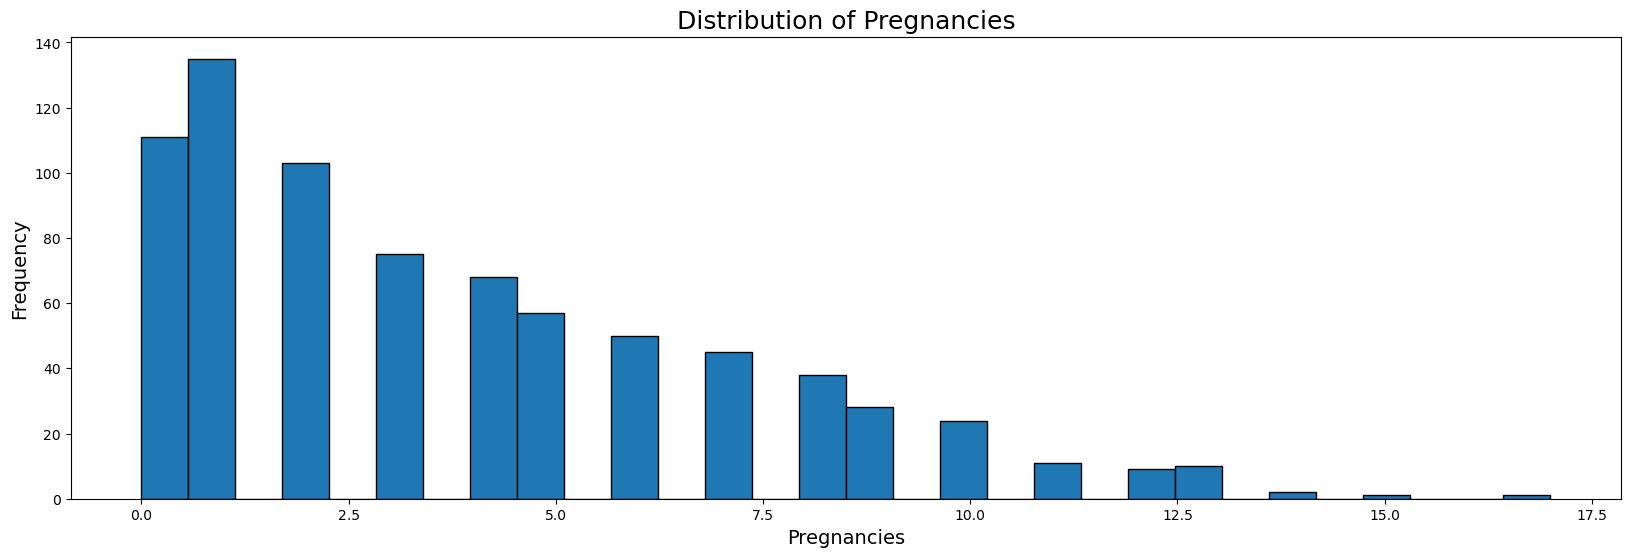

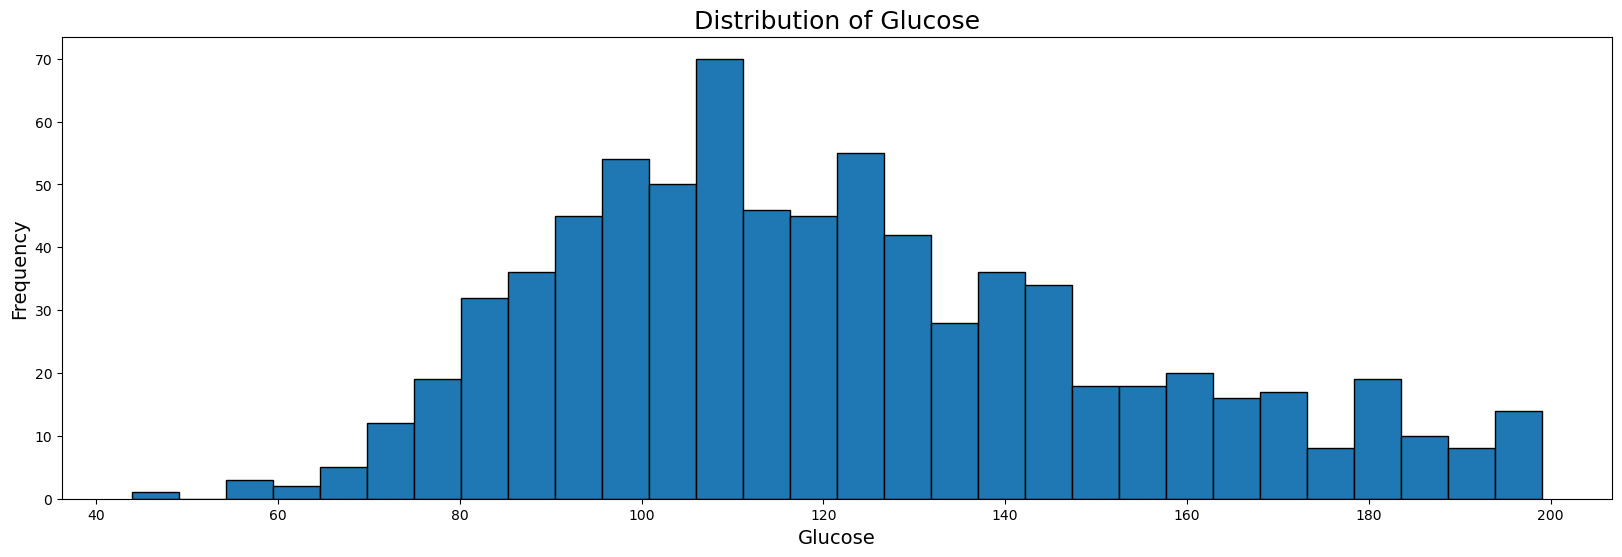

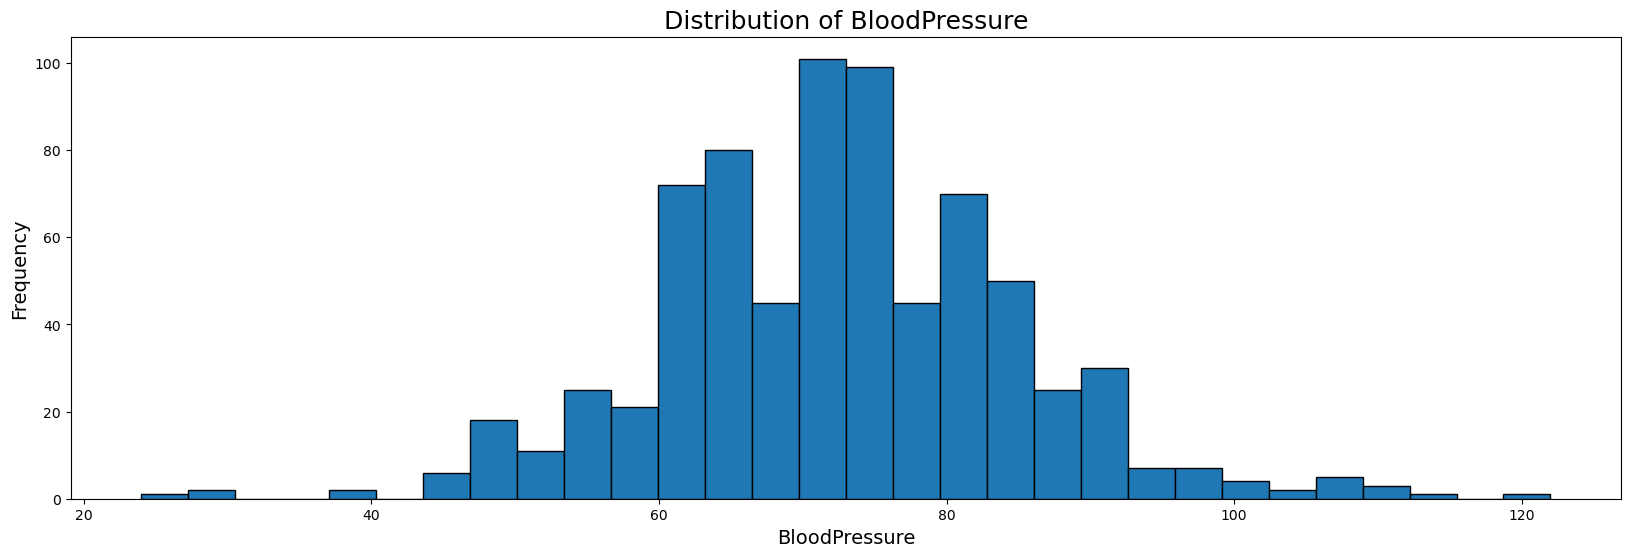

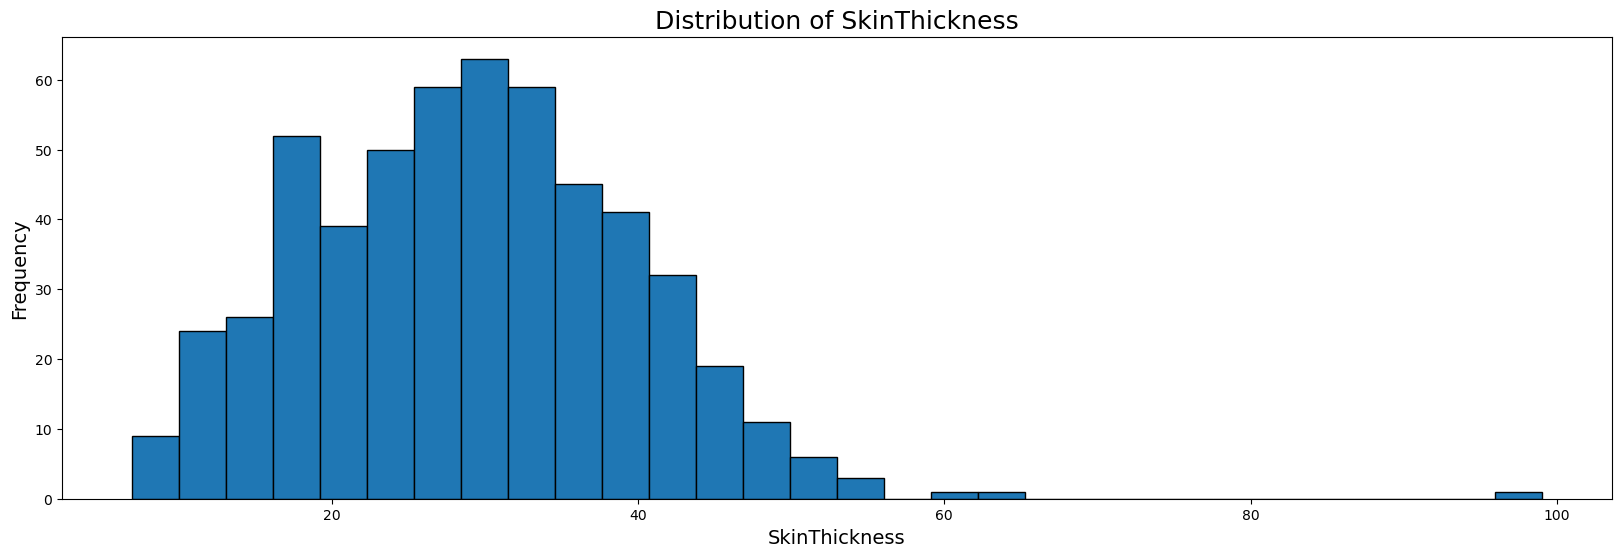

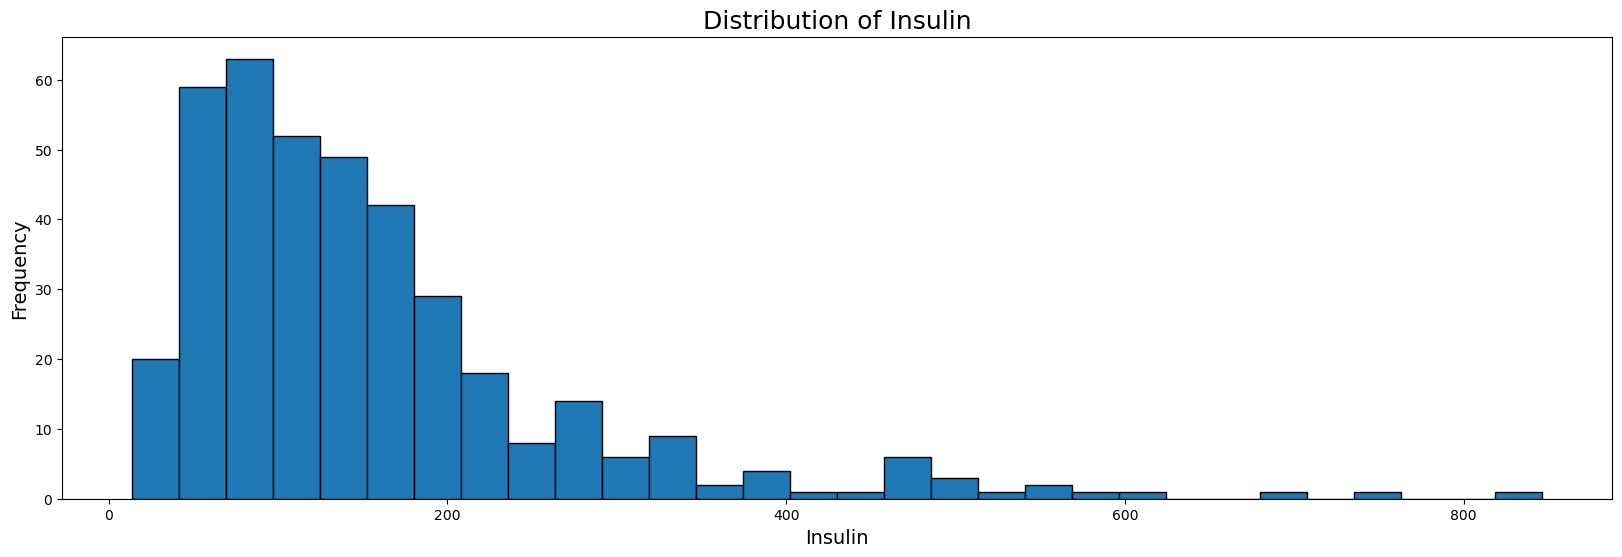

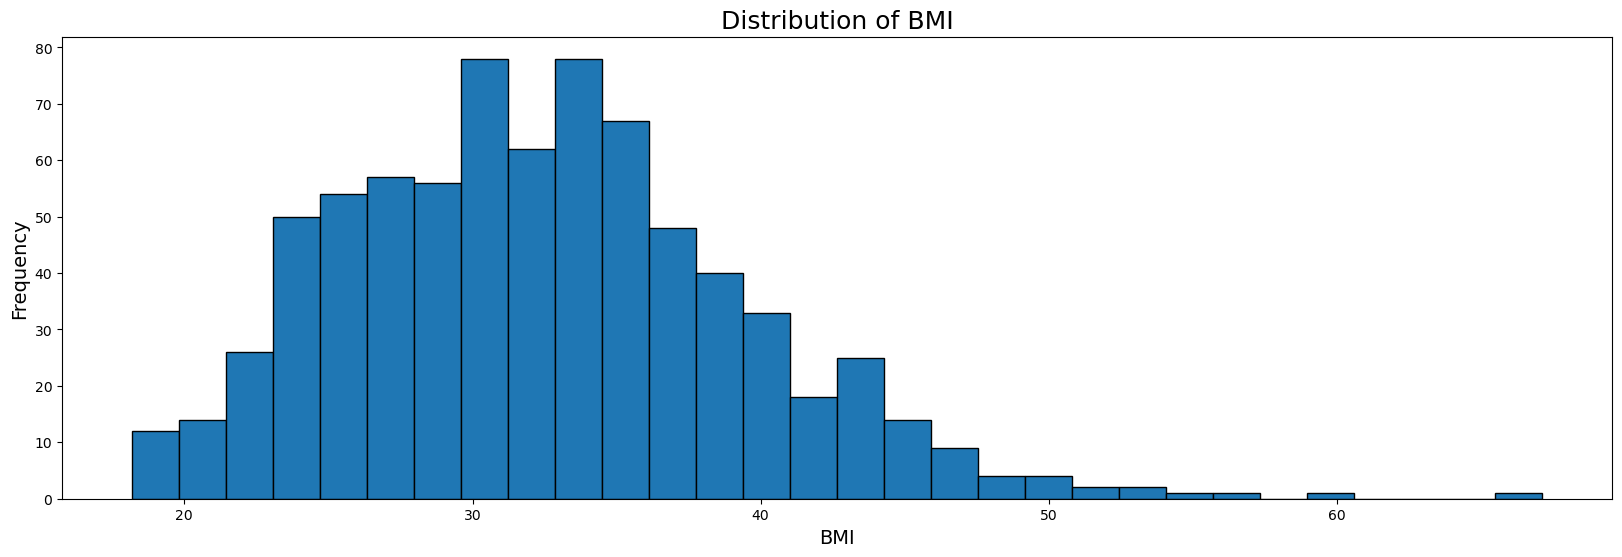

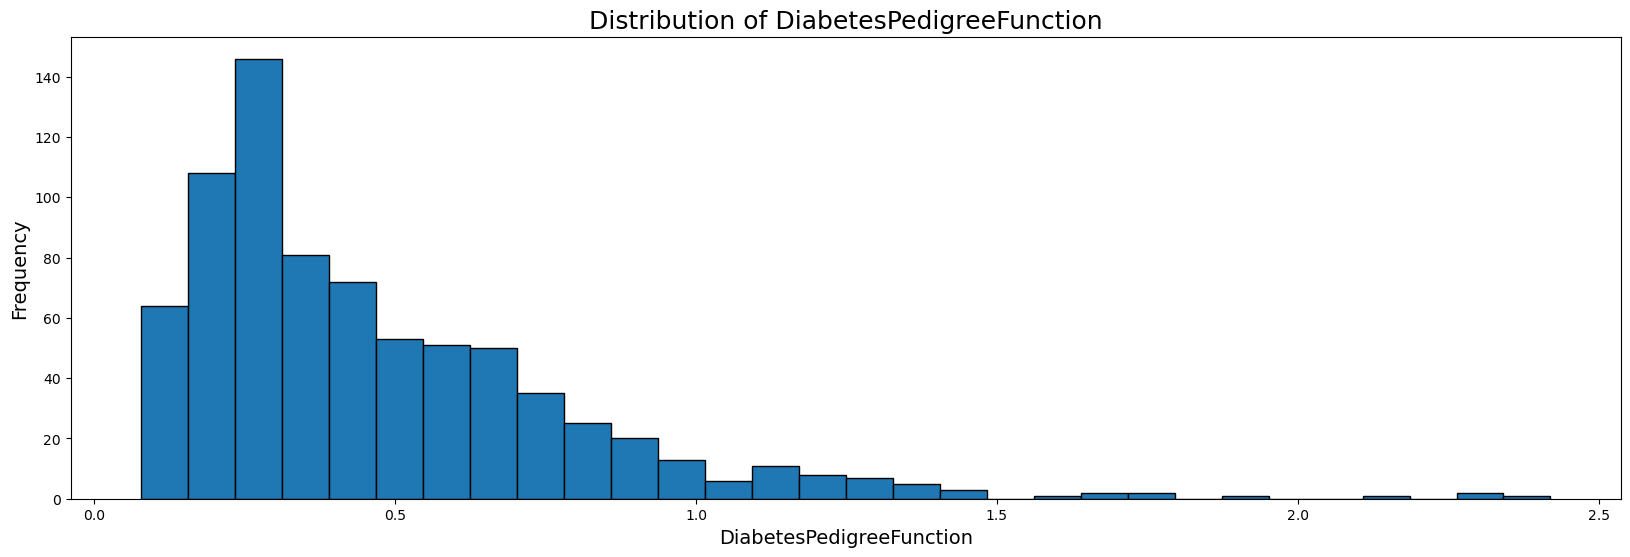

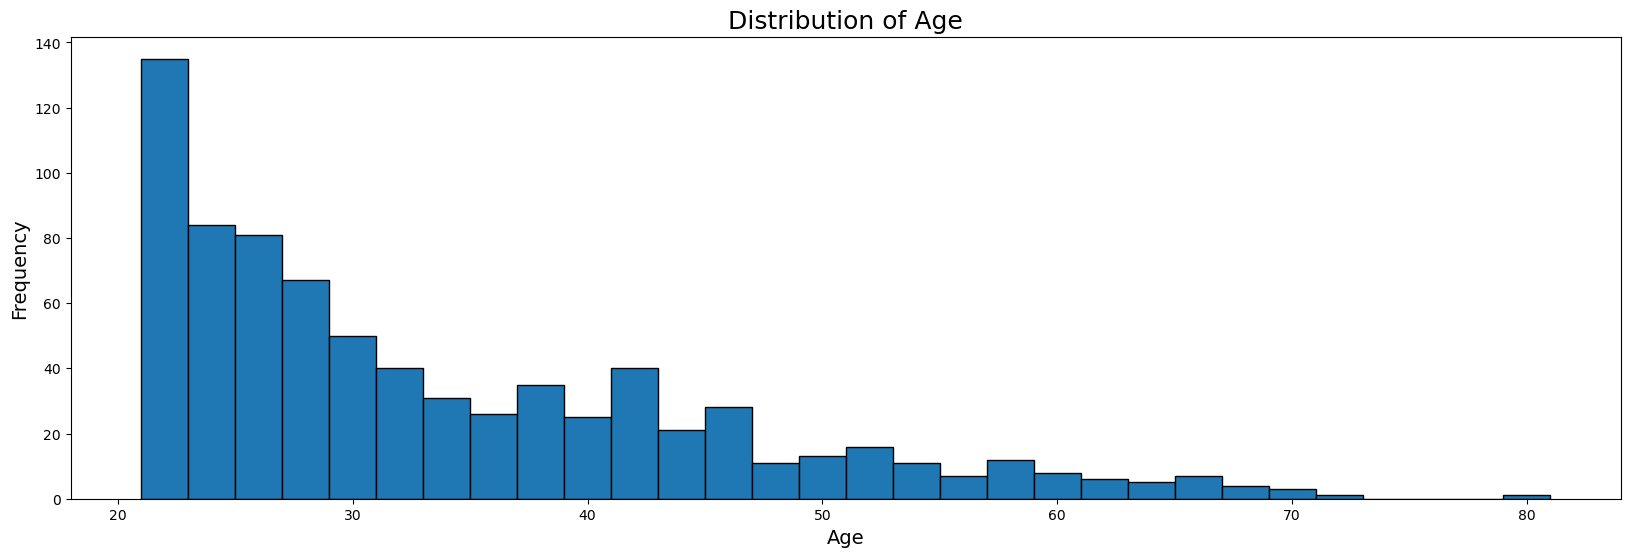

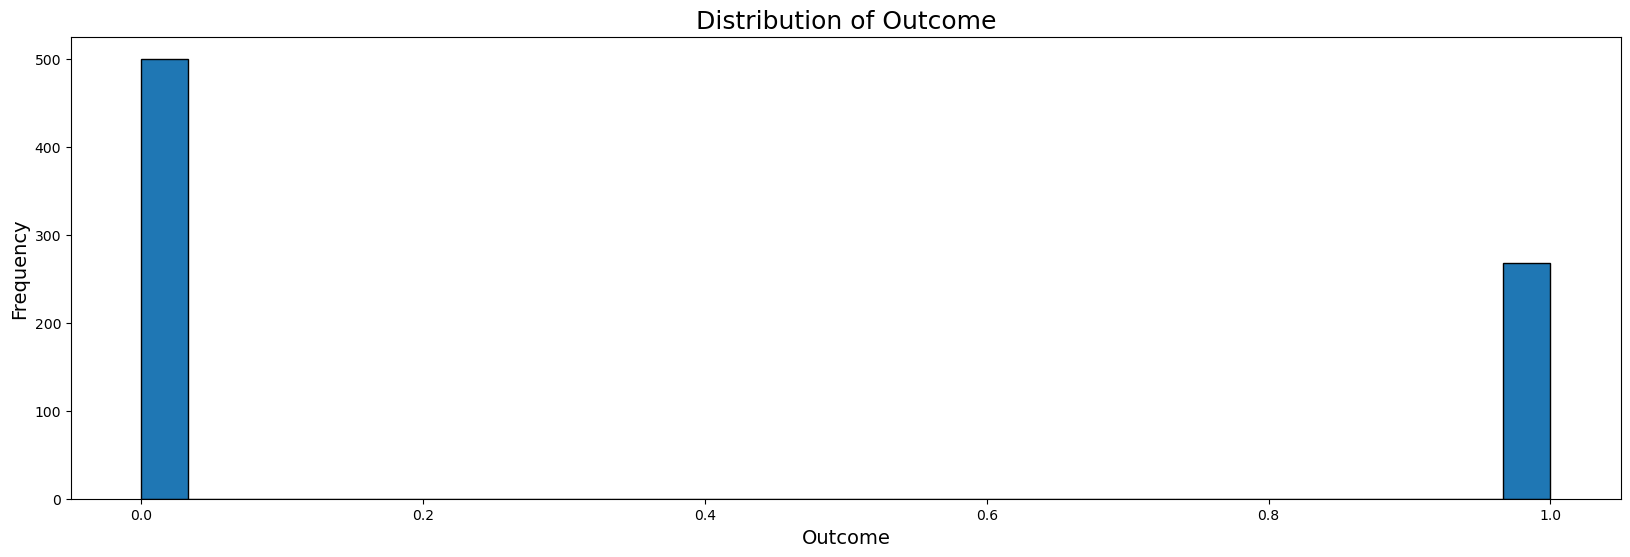

In [8]:


for col in df.columns:
    plt.figure(figsize=(20, 6))
    plt.hist(df[col].dropna(), bins=30, edgecolor='black')
    plt.title(f'Distribution of {col}', fontsize=18)
    plt.xlabel(col, fontsize=14)
    plt.ylabel('Frequency', fontsize=14)
    plt.show()

In [9]:
cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

df_filled = df.fillna(df.mean())

print(df_filled.isnull().sum())

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


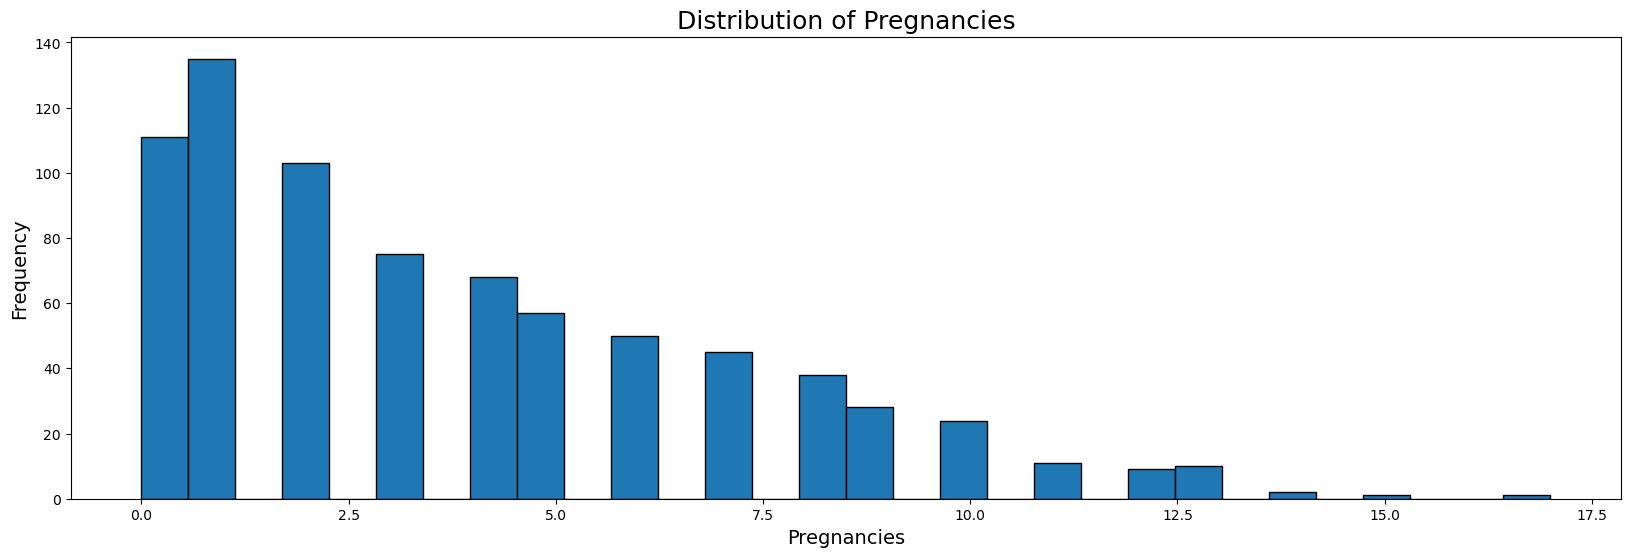

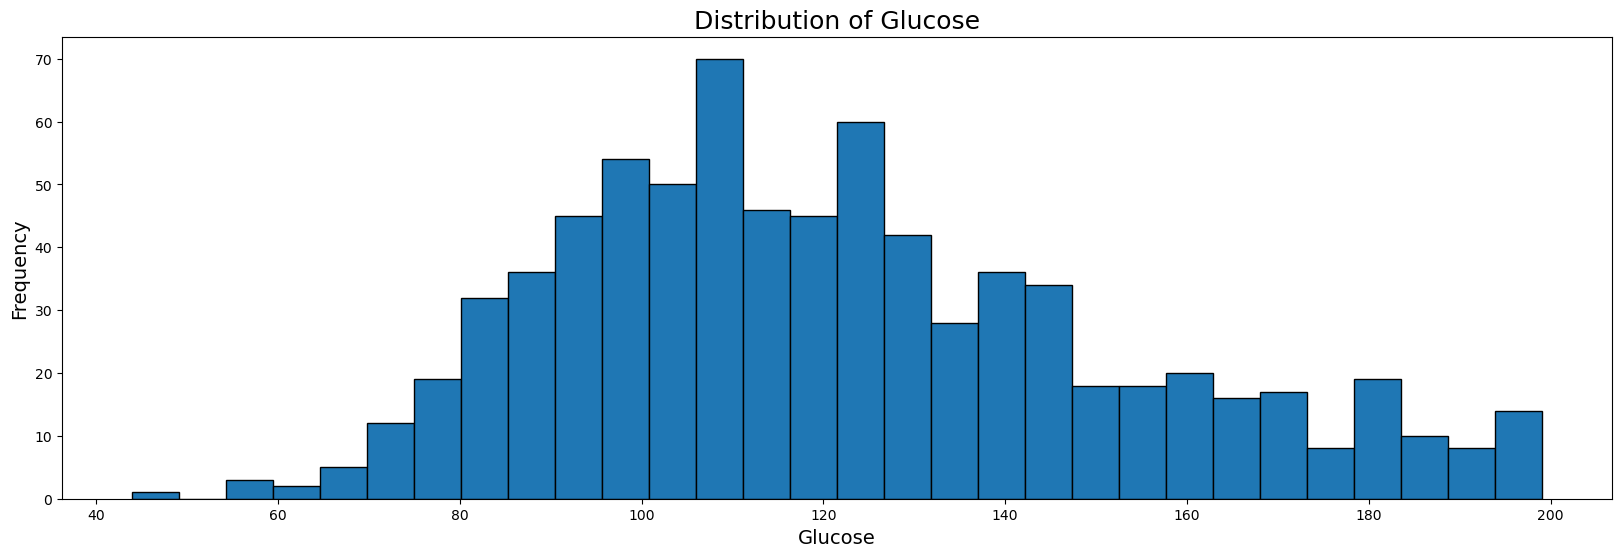

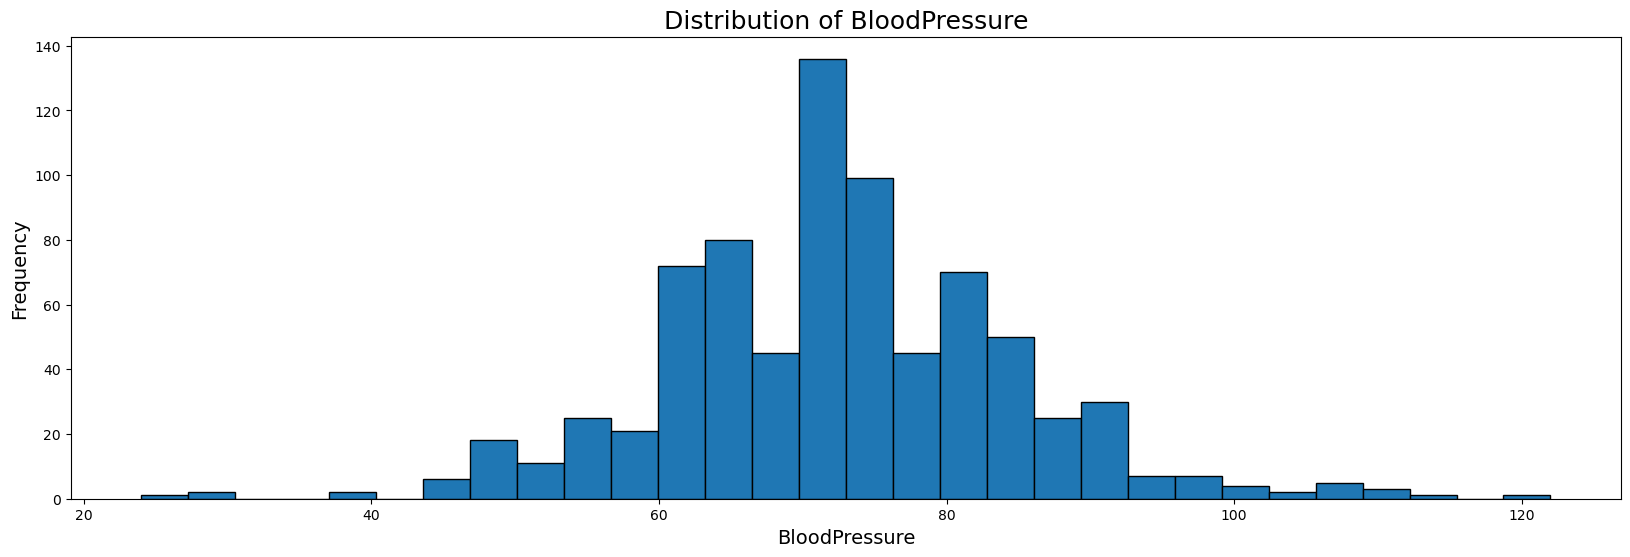

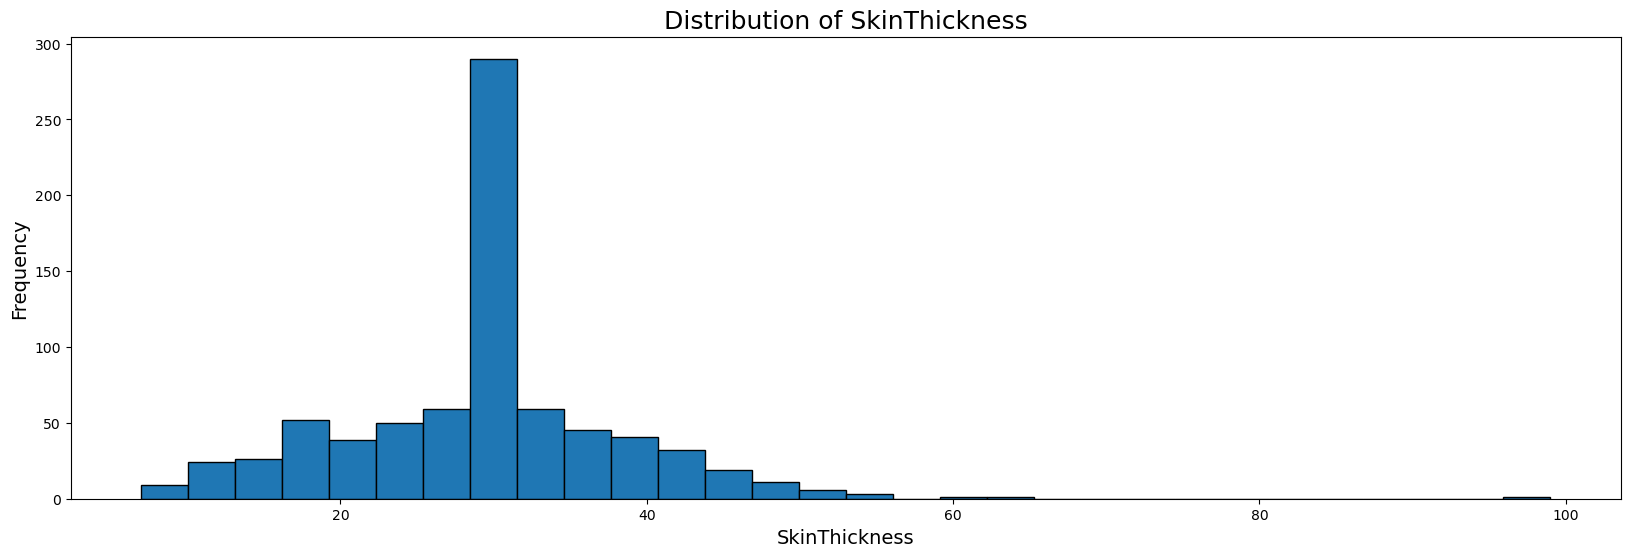

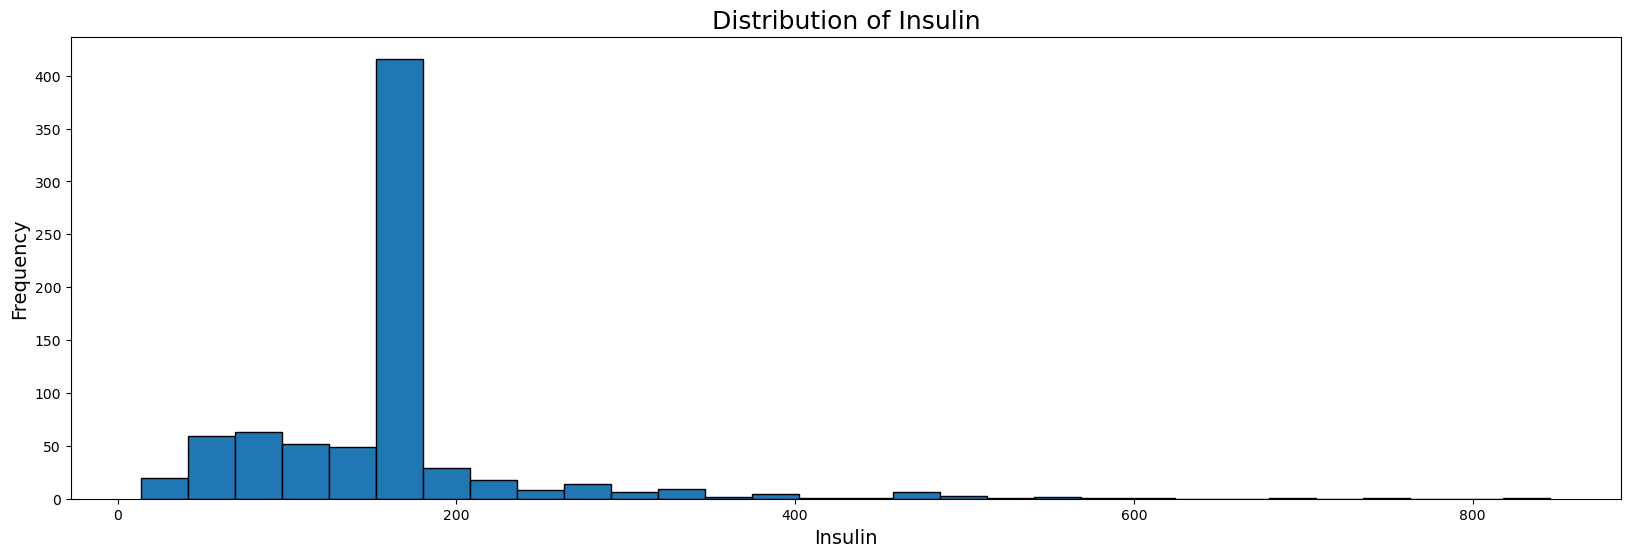

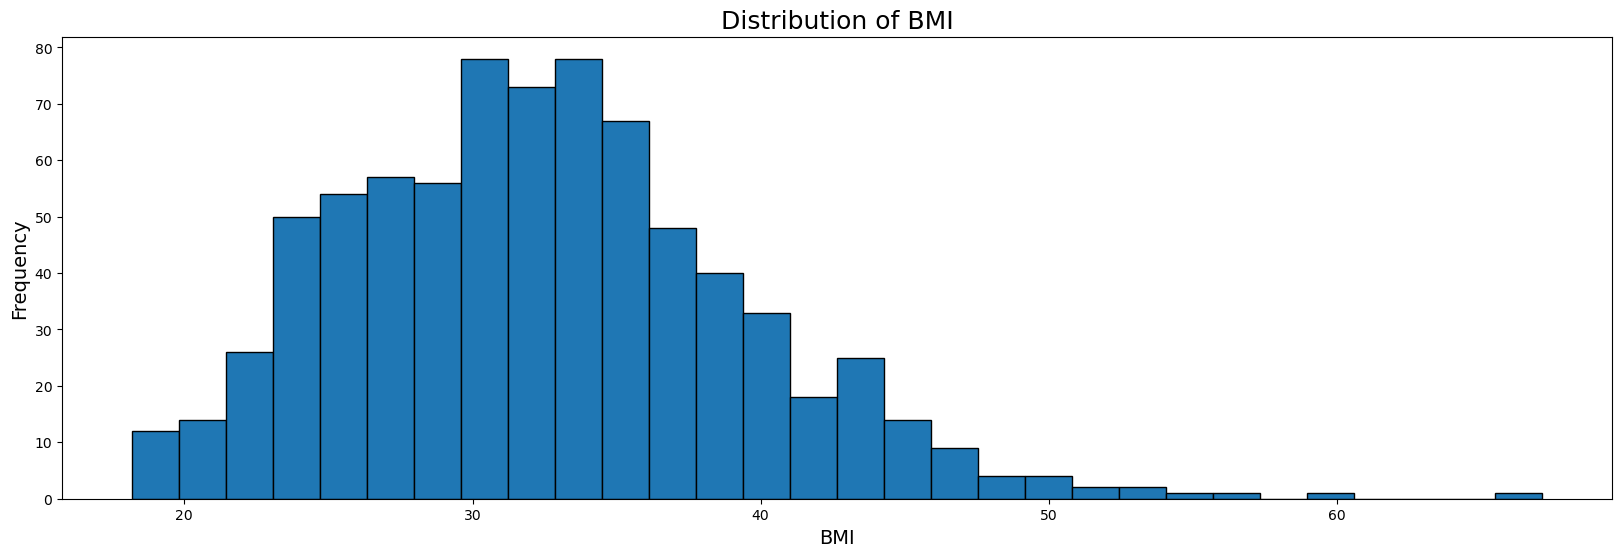

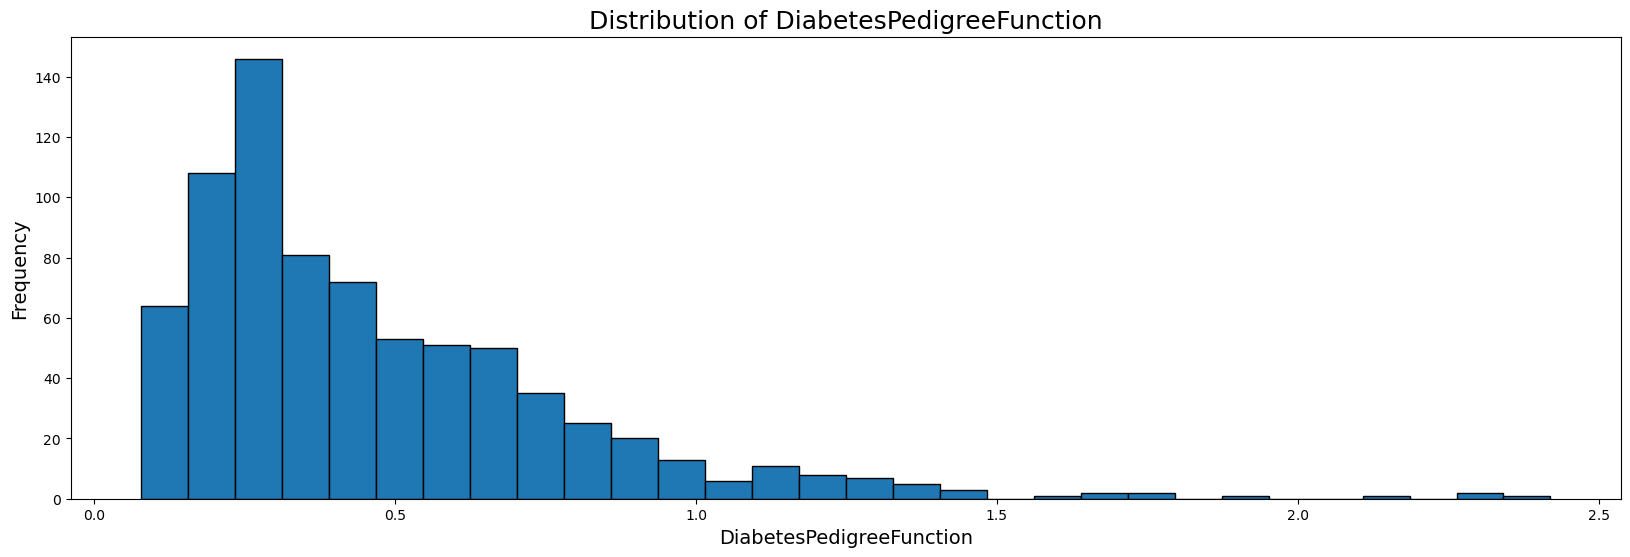

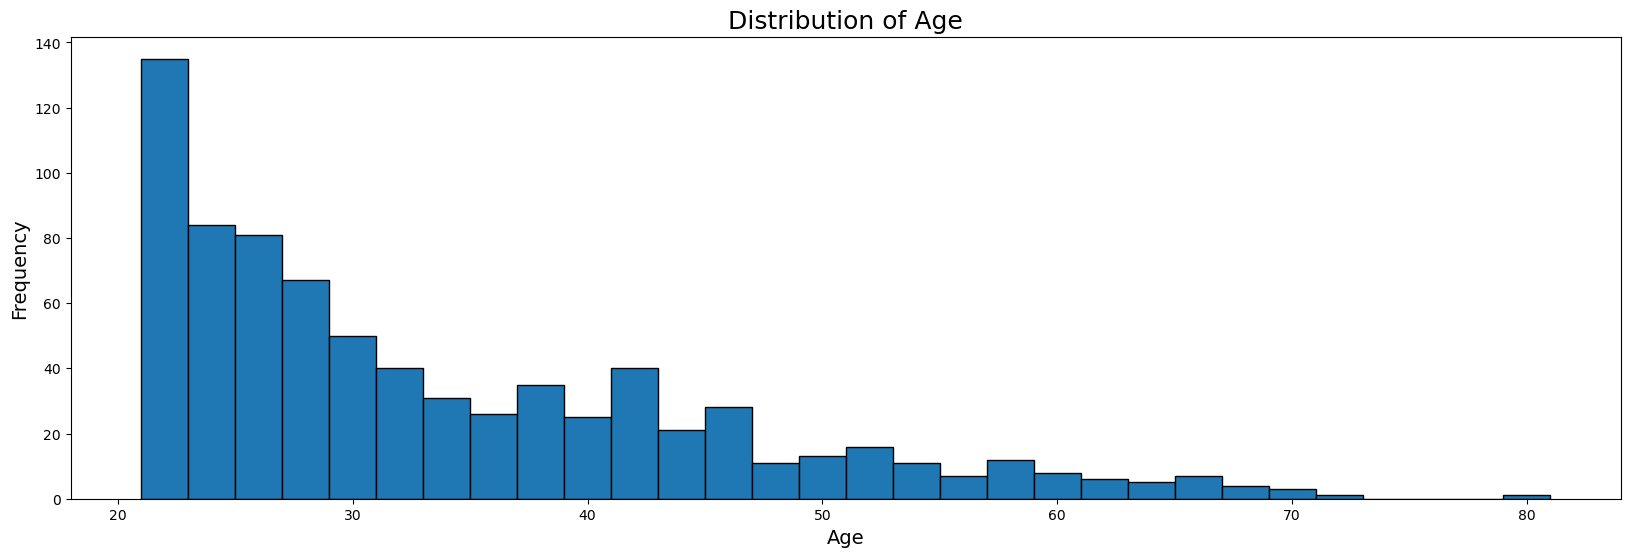

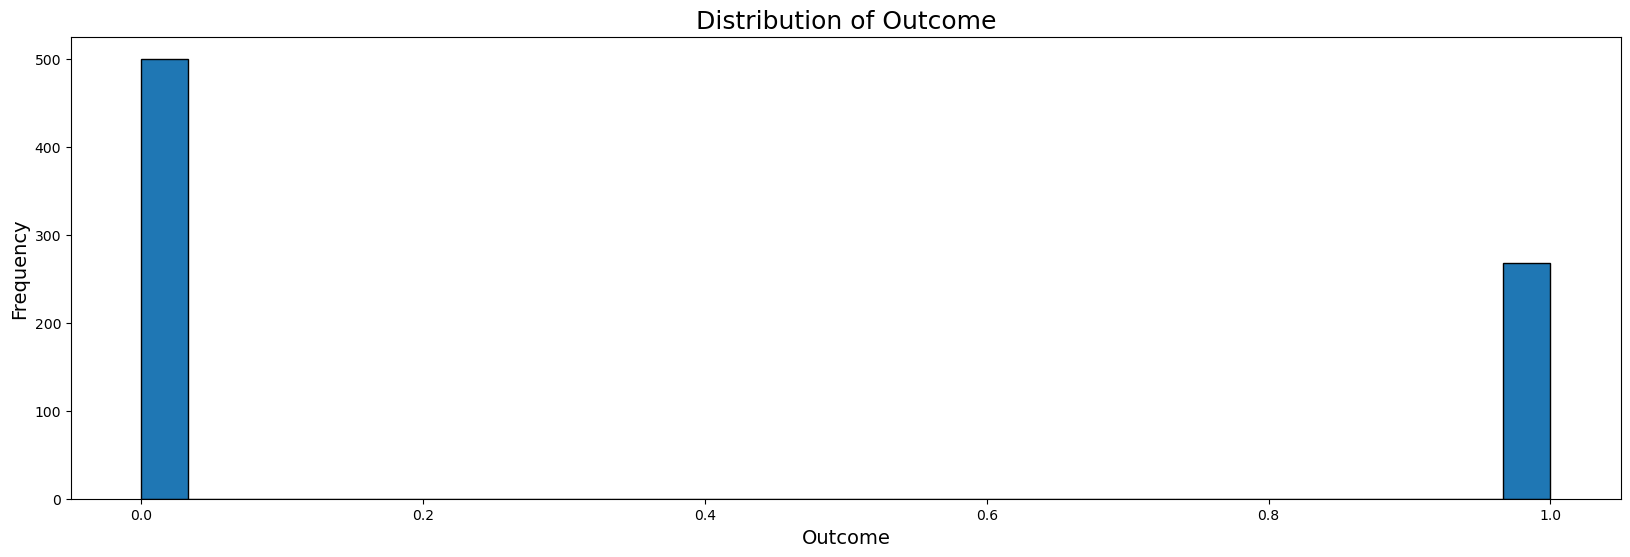

In [10]:


for col in df_filled.columns:
    plt.figure(figsize=(20, 6))
    plt.hist(df_filled[col], bins=30, edgecolor='black')
    plt.title(f'Distribution of {col}', fontsize=18)
    plt.xlabel(col, fontsize=14)
    plt.ylabel('Frequency', fontsize=14)
    plt.show()

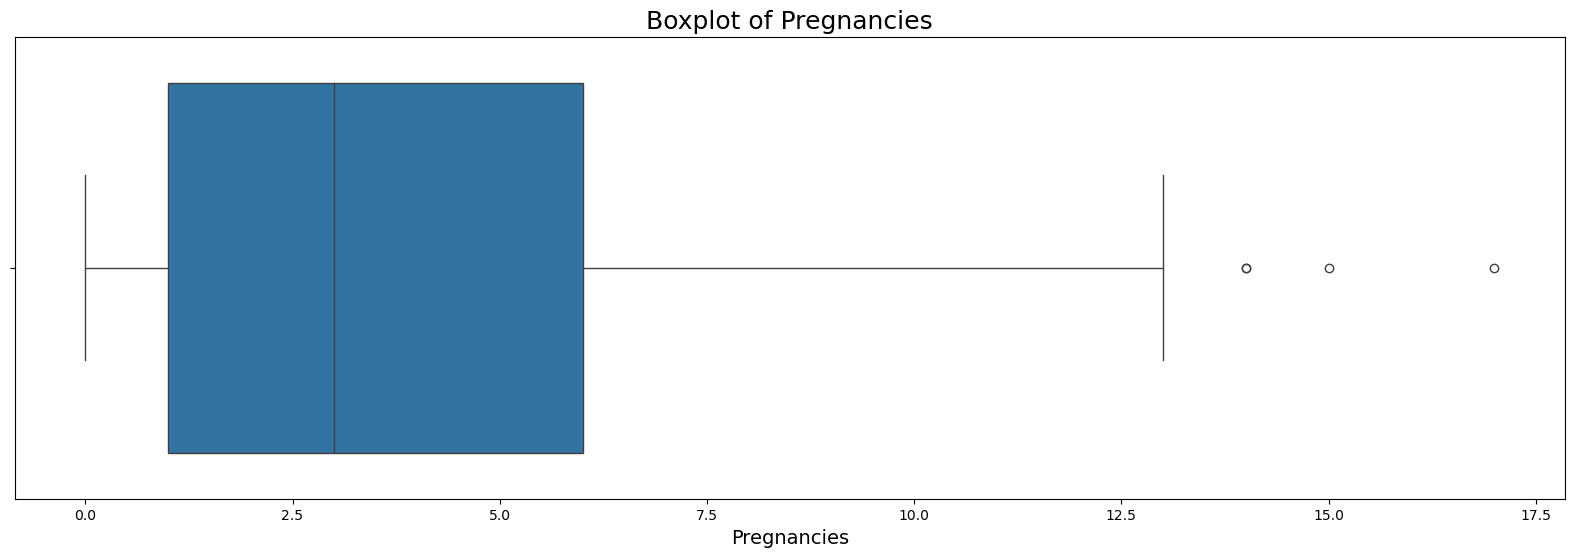

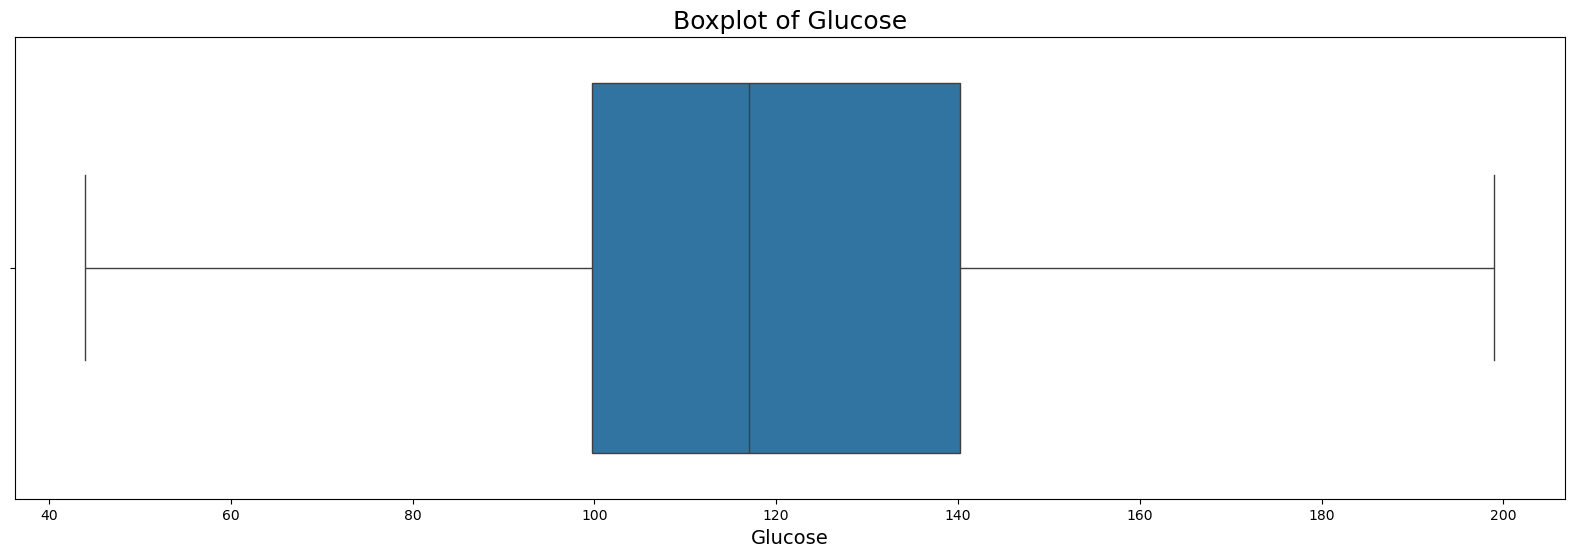

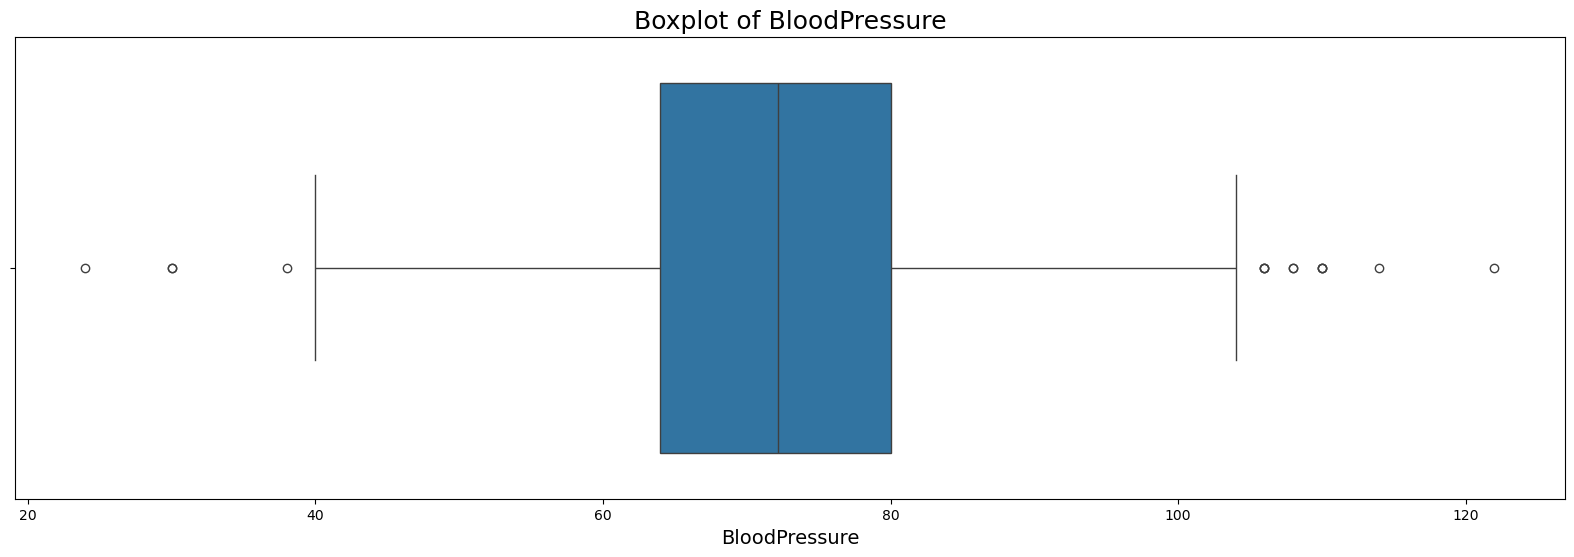

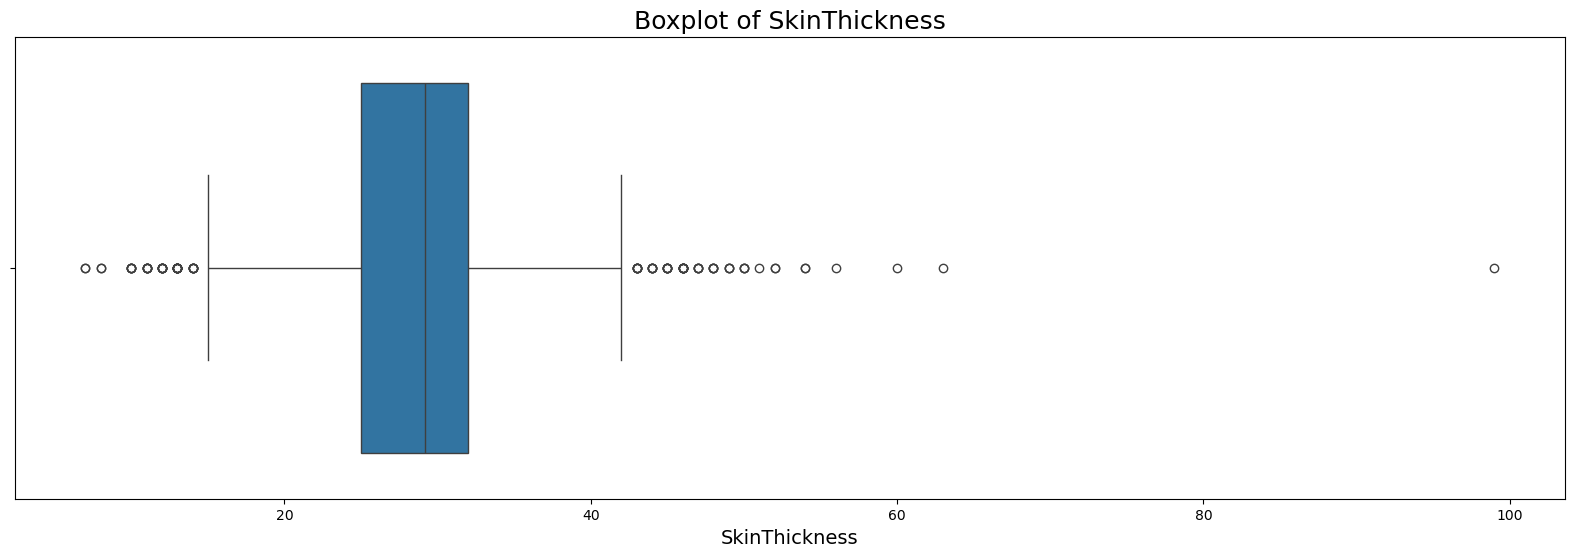

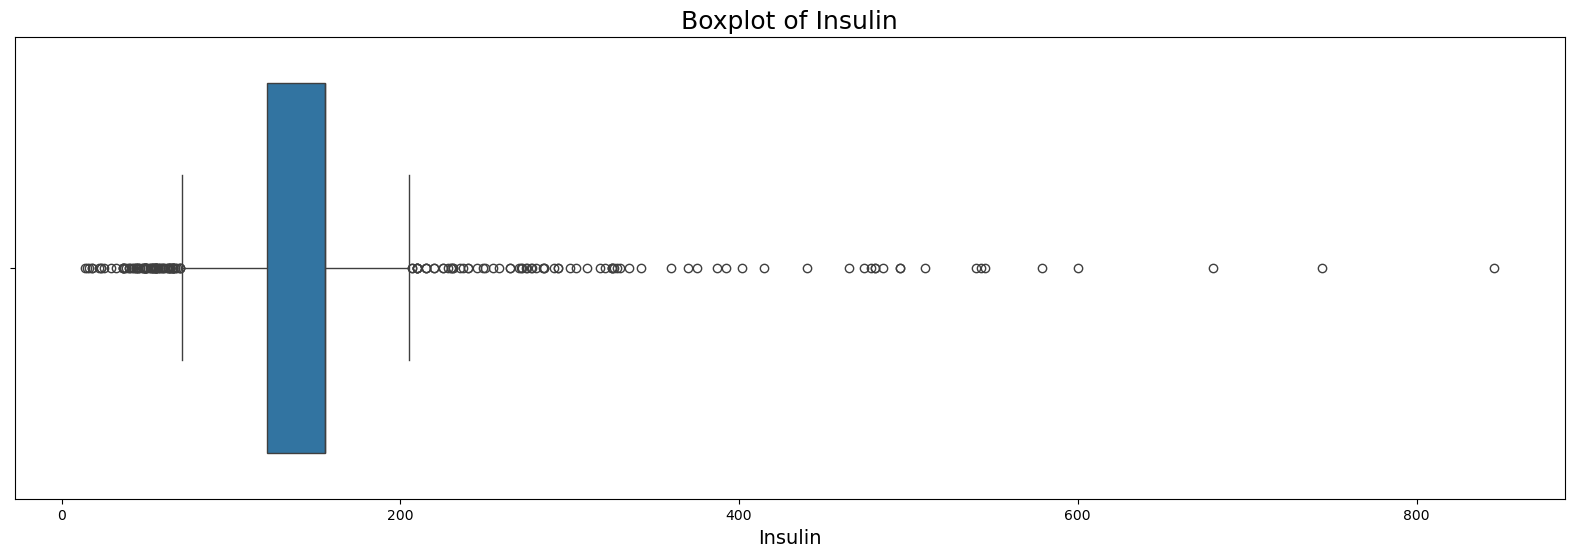

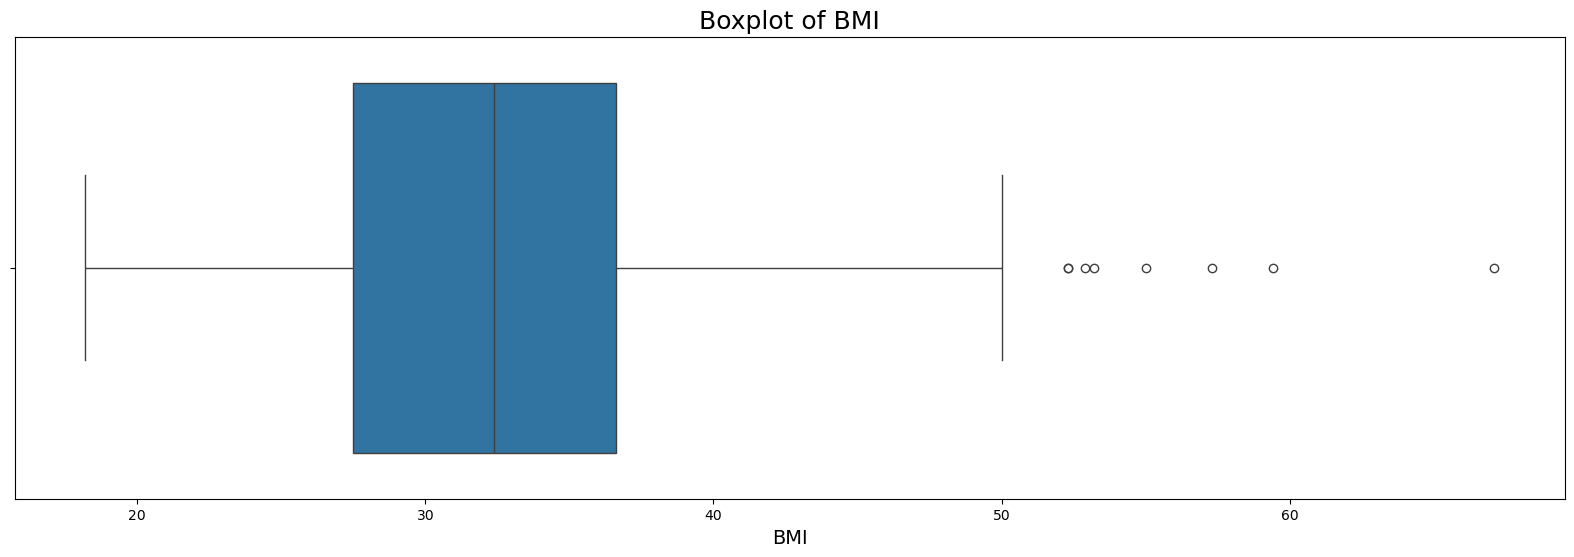

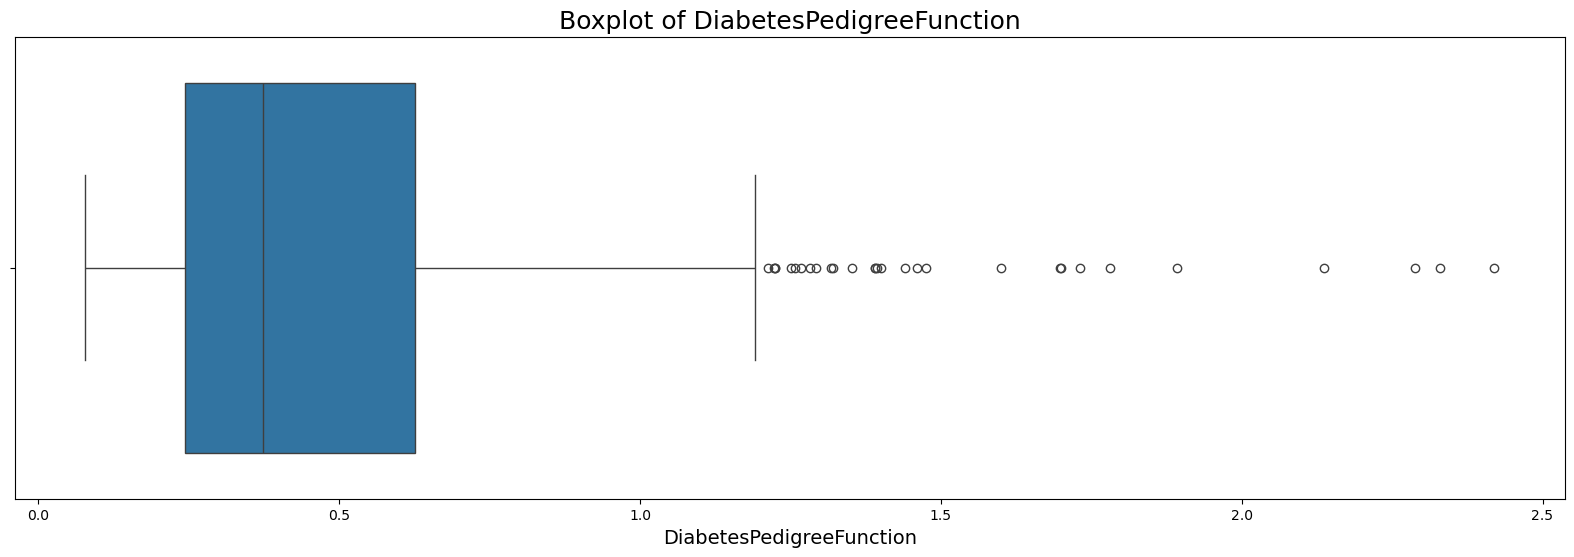

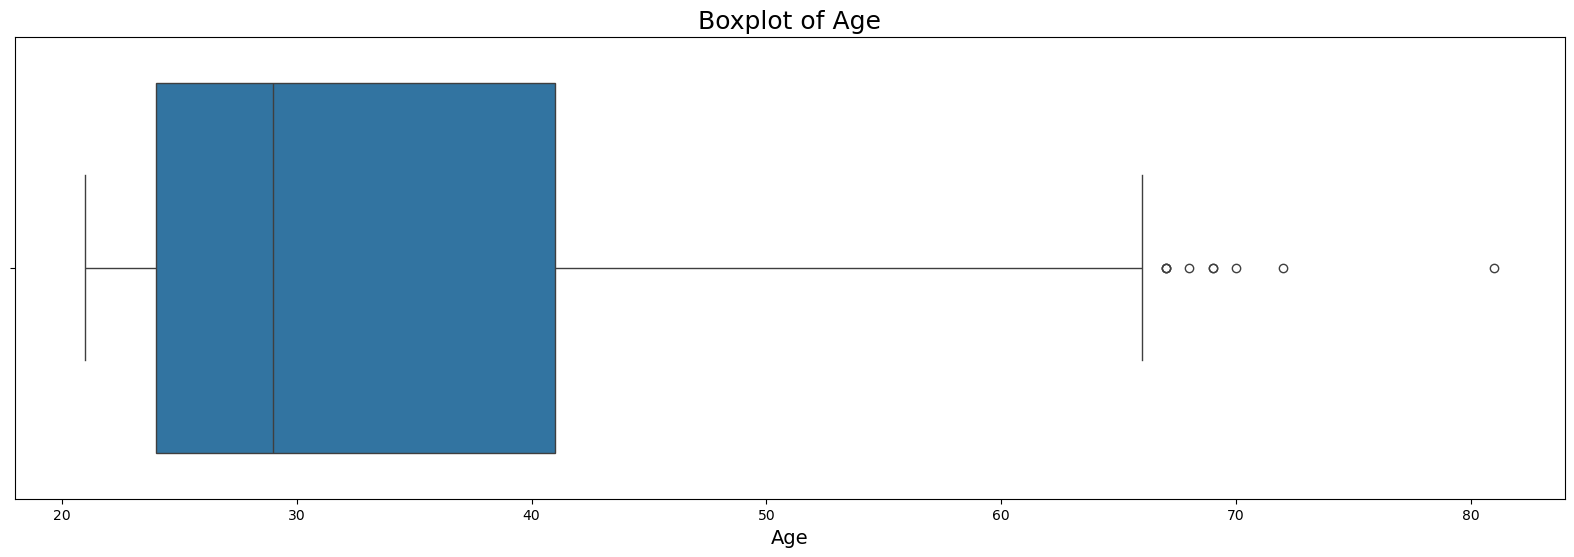

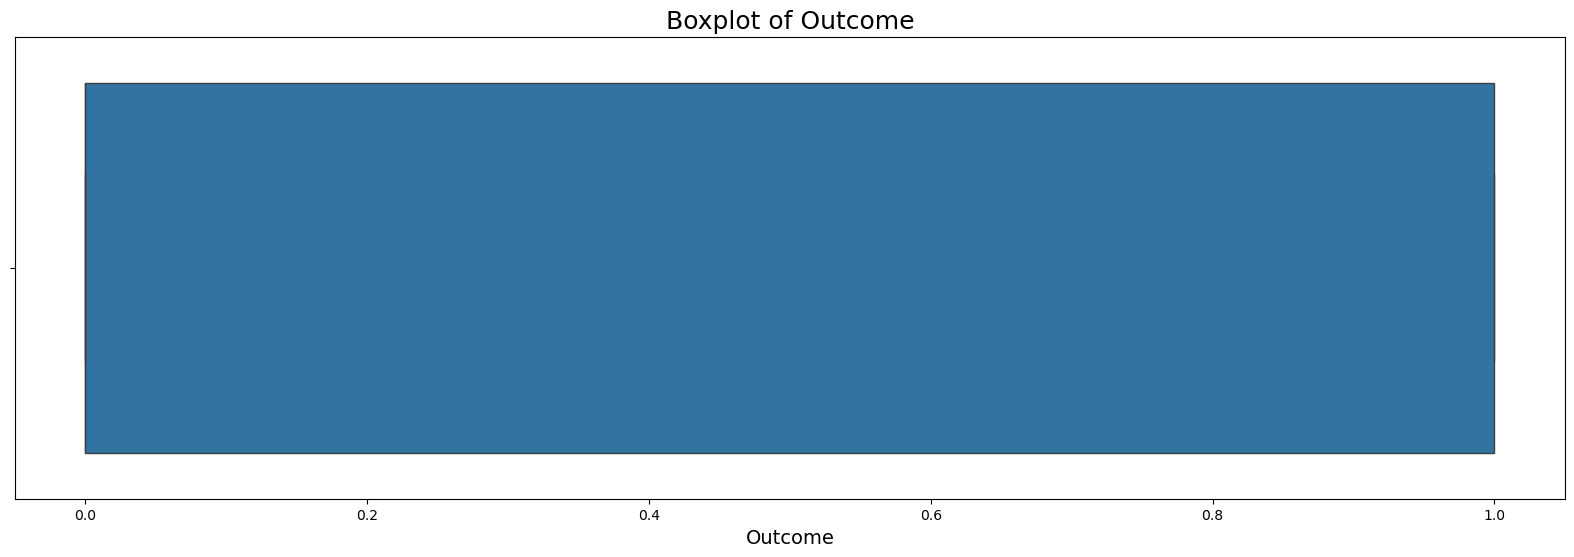

In [11]:
for col in df_filled.columns:
    plt.figure(figsize=(20, 6))
    sns.boxplot(x=df_filled[col])
    plt.title(f'Boxplot of {col}', fontsize=18)
    plt.xlabel(col, fontsize=14)
    plt.show()

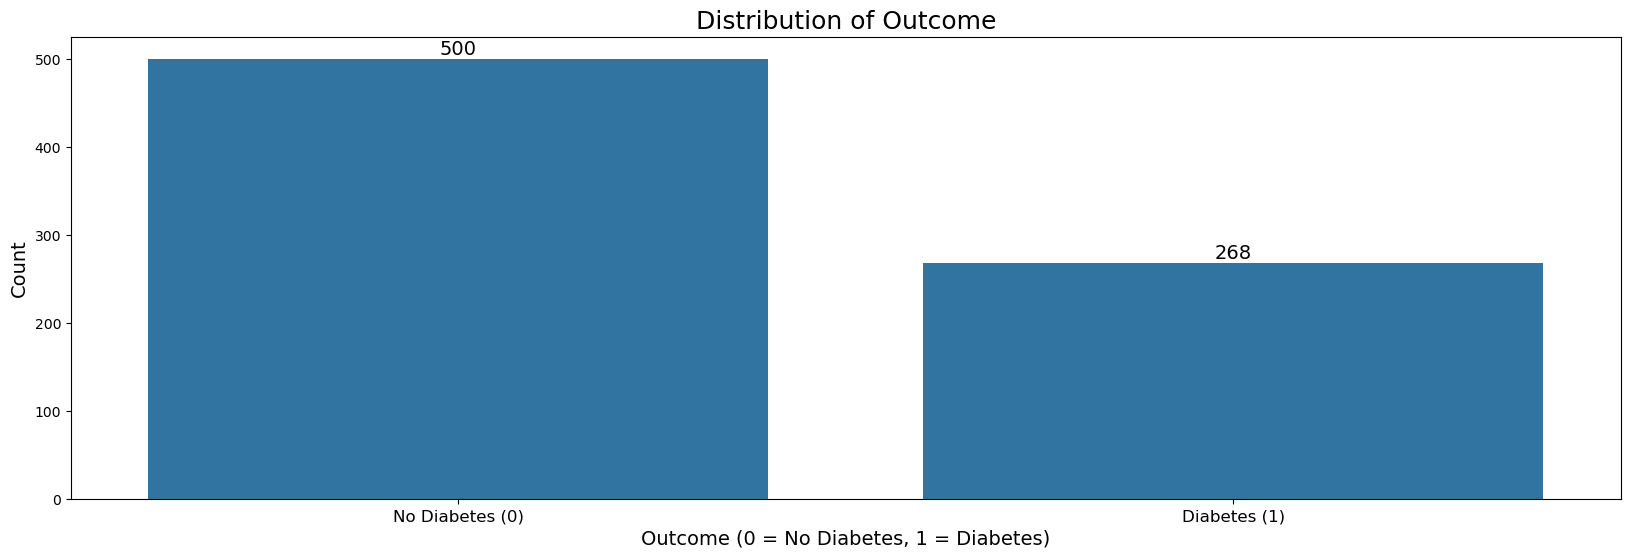

In [12]:
plt.figure(figsize=(20, 6))

ax = sns.countplot(data=df_filled, x='Outcome')

ax.bar_label(ax.containers[0], fontsize=14)

plt.title('Distribution of Outcome', fontsize=18)
plt.xlabel('Outcome (0 = No Diabetes, 1 = Diabetes)', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.xticks([0, 1], ['No Diabetes (0)', 'Diabetes (1)'], fontsize=12)

plt.show()

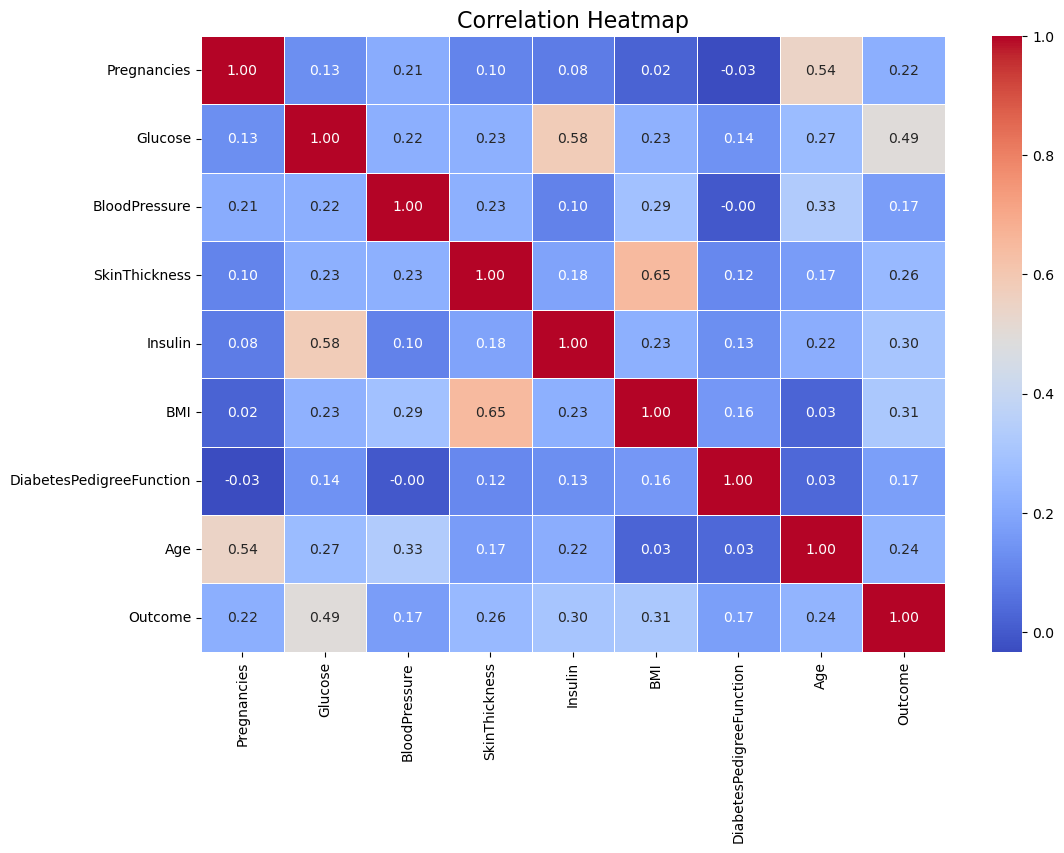

In [13]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap', fontsize=16)
plt.show()

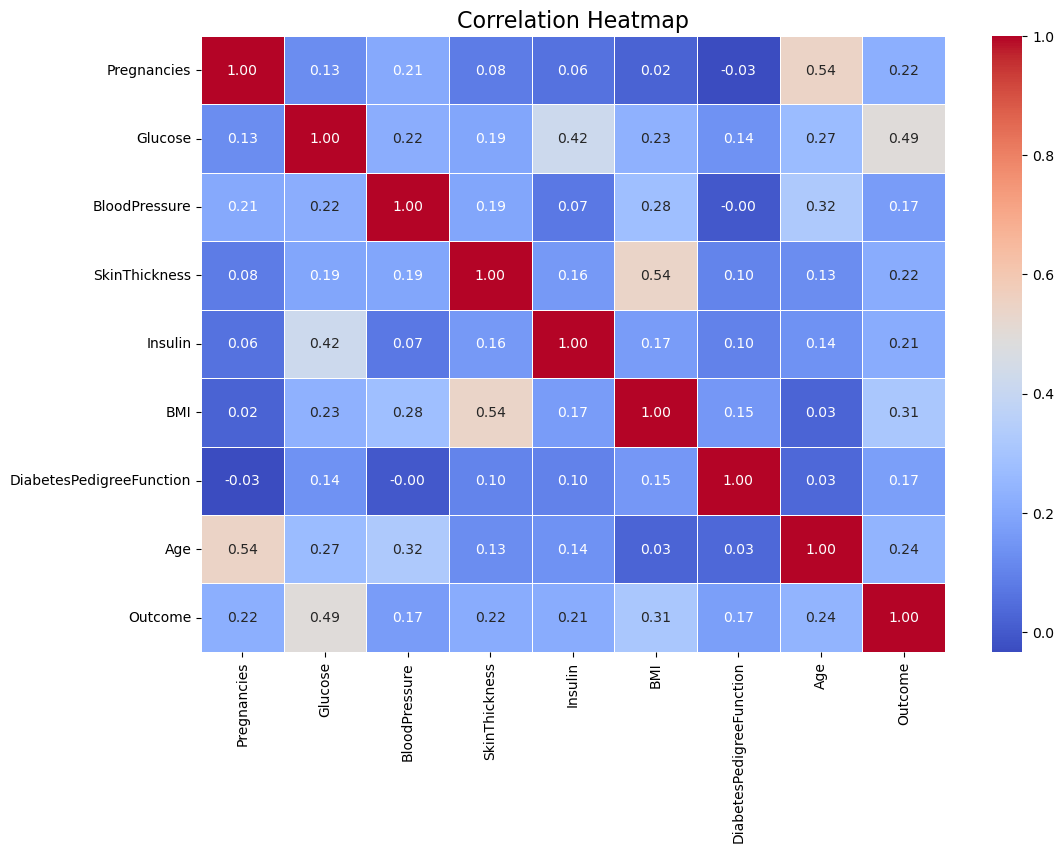

In [14]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df_filled.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap', fontsize=16)
plt.show()

In [15]:
df_filled.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.00000,155.548223,33.6,0.627,50,1
1,1,85.0,66.0,29.00000,155.548223,26.6,0.351,31,0
2,8,183.0,64.0,29.15342,155.548223,23.3,0.672,32,1
3,1,89.0,66.0,23.00000,94.000000,28.1,0.167,21,0
4,0,137.0,40.0,35.00000,168.000000,43.1,2.288,33,1


In [16]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X = df_filled.drop('Outcome', axis=1)
y = df_filled['Outcome']

X_scaled = scaler.fit_transform(X)

In [17]:
from sklearn.model_selection import train_test_split

X = df_filled.drop('Outcome', axis=1)
y = df_filled['Outcome']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (614, 8)
X_test: (154, 8)
y_train: (614,)
y_test: (154,)


## KNN Model Training and Evaluation

In [18]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    RocCurveDisplay
)
import matplotlib.pyplot as plt

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [19]:
y_pred = knn.predict(X_test_scaled)


accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("K-Nearest Neighbors (KNN) — Test Results")
print("-" * 45)
print(f"Accuracy : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

K-Nearest Neighbors (KNN) — Test Results
---------------------------------------------
Accuracy : 0.7338 (73.38%)
Precision: 0.6182
Recall   : 0.6296
F1-score : 0.6239



Classification Report:
                 precision    recall  f1-score   support

No Diabetes (0)       0.80      0.79      0.79       100
   Diabetes (1)       0.62      0.63      0.62        54

       accuracy                           0.73       154
      macro avg       0.71      0.71      0.71       154
   weighted avg       0.73      0.73      0.73       154

Confusion Matrix:
[[79 21]
 [20 34]]


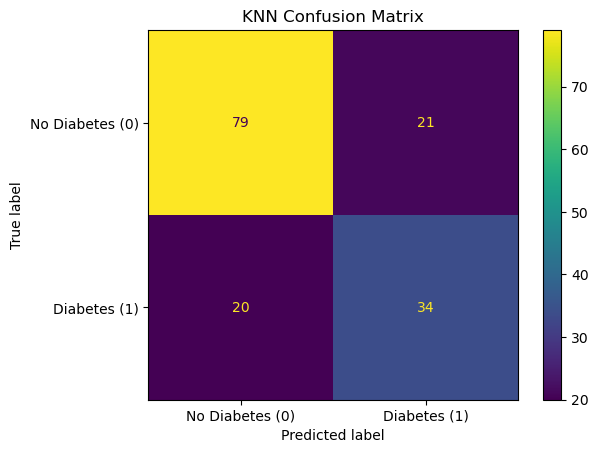

In [20]:
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Diabetes (0)", "Diabetes (1)"],
    zero_division=0
))

print("Confusion Matrix:")
cm = confusion_matrix(y_test, y_pred)
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Diabetes (0)", "Diabetes (1)"]
).plot()
plt.title("KNN Confusion Matrix")
plt.show()

ROC-AUC  : 0.7975


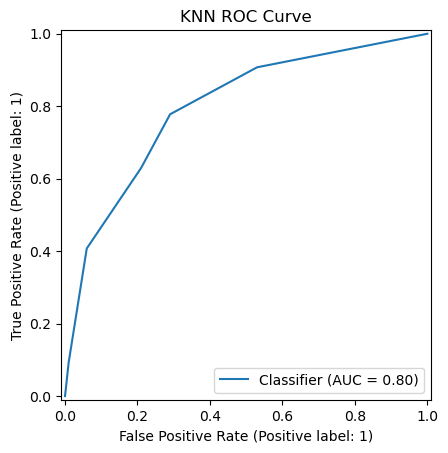

In [21]:
y_prob = knn.predict_proba(X_test_scaled)[:, 1]
print(f"ROC-AUC  : {roc_auc_score(y_test, y_prob):.4f}")

RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title("KNN ROC Curve")
plt.show()

## Logistic Regression Model Training and Evaluation

In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, RocCurveDisplay
)

logreg = LogisticRegression(max_iter=1000, random_state=42)
logreg.fit(X_train_scaled, y_train)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [23]:
y_pred_logreg = logreg.predict(X_test_scaled)

accuracy_logreg = accuracy_score(y_test, y_pred_logreg)
precision_logreg = precision_score(y_test, y_pred_logreg, zero_division=0)
recall_logreg = recall_score(y_test, y_pred_logreg, zero_division=0)
f1_logreg = f1_score(y_test, y_pred_logreg, zero_division=0)

print("Logistic Regression — Test Results")
print("-" * 45)
print(f"Accuracy : {accuracy_logreg:.4f} ({accuracy_logreg * 100:.2f}%)")
print(f"Precision: {precision_logreg:.4f}")
print(f"Recall   : {recall_logreg:.4f}")
print(f"F1-score : {f1_logreg:.4f}")


Logistic Regression — Test Results
---------------------------------------------
Accuracy : 0.6948 (69.48%)
Precision: 0.5778
Recall   : 0.4815
F1-score : 0.5253


\nClassification Report:
                 precision    recall  f1-score   support

No Diabetes (0)       0.74      0.81      0.78       100
   Diabetes (1)       0.58      0.48      0.53        54

       accuracy                           0.69       154
      macro avg       0.66      0.65      0.65       154
   weighted avg       0.69      0.69      0.69       154

Confusion Matrix:
[[81 19]
 [28 26]]


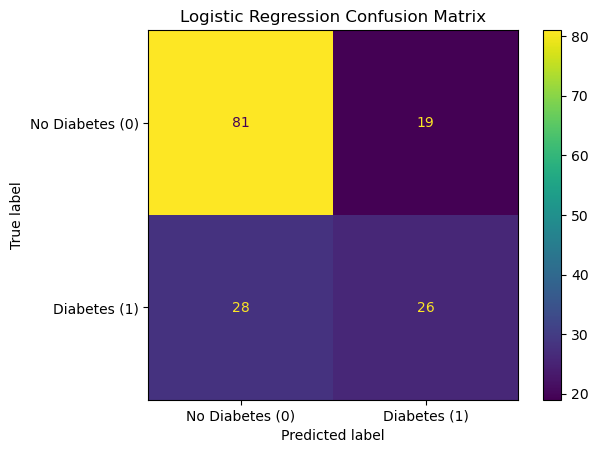

In [24]:
print("\\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_logreg,
    target_names=["No Diabetes (0)", "Diabetes (1)"],
    zero_division=0
))

print("Confusion Matrix:")
cm_logreg = confusion_matrix(y_test, y_pred_logreg)
print(cm_logreg)

ConfusionMatrixDisplay(
    confusion_matrix=cm_logreg,
    display_labels=["No Diabetes (0)", "Diabetes (1)"]
).plot()
plt.title("Logistic Regression Confusion Matrix")
plt.show()


ROC-AUC  : 0.8117


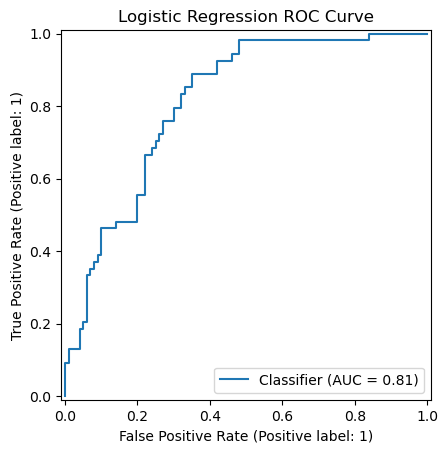

In [25]:
y_prob_logreg = logreg.predict_proba(X_test_scaled)[:, 1]
print(f"ROC-AUC  : {roc_auc_score(y_test, y_prob_logreg):.4f}")

RocCurveDisplay.from_predictions(y_test, y_prob_logreg)
plt.title("Logistic Regression ROC Curve")
plt.show()


## Support Vector Machine (SVM) Model Training and Evaluation

In [26]:
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, RocCurveDisplay
)

svm = SVC(kernel='rbf', probability=True, random_state=42)
svm.fit(X_train_scaled, y_train)


,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,True
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [27]:
y_pred_svm = svm.predict(X_test_scaled)

accuracy_svm = accuracy_score(y_test, y_pred_svm)
precision_svm = precision_score(y_test, y_pred_svm, zero_division=0)
recall_svm = recall_score(y_test, y_pred_svm, zero_division=0)
f1_svm = f1_score(y_test, y_pred_svm, zero_division=0)

print("Support Vector Machine (SVM) — Test Results")
print("-" * 45)
print(f"Accuracy : {accuracy_svm:.4f} ({accuracy_svm * 100:.2f}%)")
print(f"Precision: {precision_svm:.4f}")
print(f"Recall   : {recall_svm:.4f}")
print(f"F1-score : {f1_svm:.4f}")


Support Vector Machine (SVM) — Test Results
---------------------------------------------
Accuracy : 0.7338 (73.38%)
Precision: 0.6444
Recall   : 0.5370
F1-score : 0.5859


\nClassification Report:
                 precision    recall  f1-score   support

No Diabetes (0)       0.77      0.84      0.80       100
   Diabetes (1)       0.64      0.54      0.59        54

       accuracy                           0.73       154
      macro avg       0.71      0.69      0.69       154
   weighted avg       0.73      0.73      0.73       154

Confusion Matrix:
[[84 16]
 [25 29]]


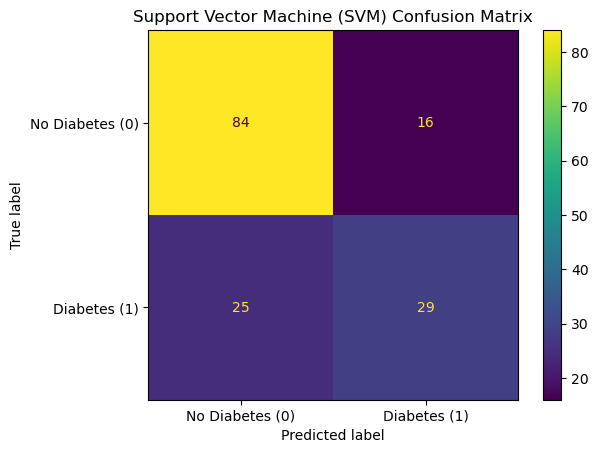

In [28]:
print("\\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_svm,
    target_names=["No Diabetes (0)", "Diabetes (1)"],
    zero_division=0
))

print("Confusion Matrix:")
cm_svm = confusion_matrix(y_test, y_pred_svm)
print(cm_svm)

ConfusionMatrixDisplay(
    confusion_matrix=cm_svm,
    display_labels=["No Diabetes (0)", "Diabetes (1)"]
).plot()
plt.title("Support Vector Machine (SVM) Confusion Matrix")
plt.show()


ROC-AUC  : 0.7912


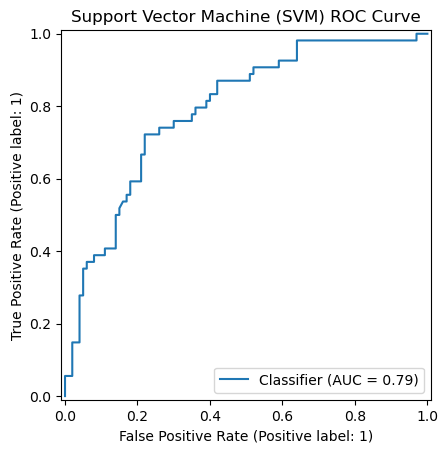

In [29]:
y_prob_svm = svm.predict_proba(X_test_scaled)[:, 1]
print(f"ROC-AUC  : {roc_auc_score(y_test, y_prob_svm):.4f}")

RocCurveDisplay.from_predictions(y_test, y_prob_svm)
plt.title("Support Vector Machine (SVM) ROC Curve")
plt.show()


## Decision Tree Model Training and Evaluation

In [30]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, RocCurveDisplay
)

decision_tree = DecisionTreeClassifier(random_state=42)
decision_tree.fit(X_train, y_train)


,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [31]:
y_pred_decision_tree = decision_tree.predict(X_test)

accuracy_decision_tree = accuracy_score(y_test, y_pred_decision_tree)
precision_decision_tree = precision_score(y_test, y_pred_decision_tree, zero_division=0)
recall_decision_tree = recall_score(y_test, y_pred_decision_tree, zero_division=0)
f1_decision_tree = f1_score(y_test, y_pred_decision_tree, zero_division=0)

print("Decision Tree — Test Results")
print("-" * 45)
print(f"Accuracy : {accuracy_decision_tree:.4f} ({accuracy_decision_tree * 100:.2f}%)")
print(f"Precision: {precision_decision_tree:.4f}")
print(f"Recall   : {recall_decision_tree:.4f}")
print(f"F1-score : {f1_decision_tree:.4f}")


Decision Tree — Test Results
---------------------------------------------
Accuracy : 0.6688 (66.88%)
Precision: 0.5333
Recall   : 0.4444
F1-score : 0.4848


\nClassification Report:
                 precision    recall  f1-score   support

No Diabetes (0)       0.72      0.79      0.76       100
   Diabetes (1)       0.53      0.44      0.48        54

       accuracy                           0.67       154
      macro avg       0.63      0.62      0.62       154
   weighted avg       0.66      0.67      0.66       154

Confusion Matrix:
[[79 21]
 [30 24]]


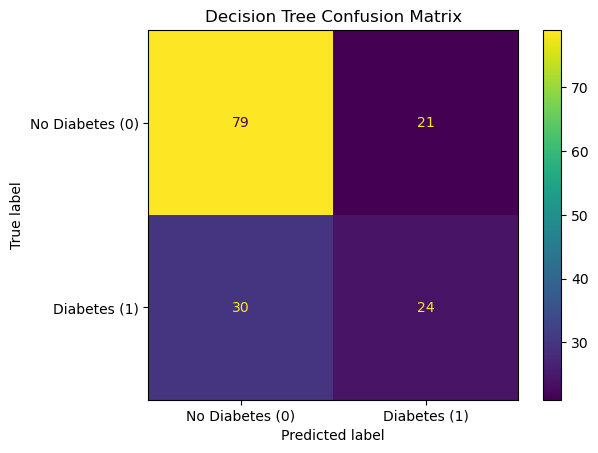

In [32]:
print("\\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_decision_tree,
    target_names=["No Diabetes (0)", "Diabetes (1)"],
    zero_division=0
))

print("Confusion Matrix:")
cm_decision_tree = confusion_matrix(y_test, y_pred_decision_tree)
print(cm_decision_tree)

ConfusionMatrixDisplay(
    confusion_matrix=cm_decision_tree,
    display_labels=["No Diabetes (0)", "Diabetes (1)"]
).plot()
plt.title("Decision Tree Confusion Matrix")
plt.show()


ROC-AUC  : 0.6172


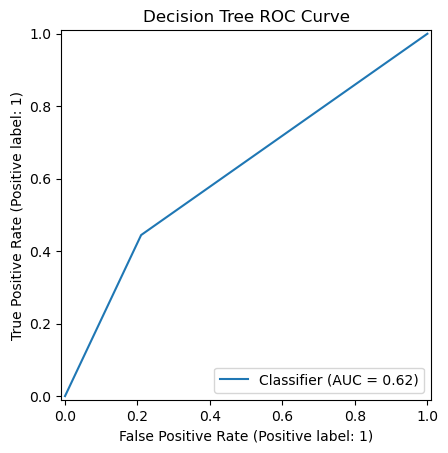

In [33]:
y_prob_decision_tree = decision_tree.predict_proba(X_test)[:, 1]
print(f"ROC-AUC  : {roc_auc_score(y_test, y_prob_decision_tree):.4f}")

RocCurveDisplay.from_predictions(y_test, y_prob_decision_tree)
plt.title("Decision Tree ROC Curve")
plt.show()


## Random Forest Model Training and Evaluation

In [34]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, RocCurveDisplay
)

random_forest = RandomForestClassifier(n_estimators=200, random_state=42)
random_forest.fit(X_train, y_train)


,n_estimators,200
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [35]:
y_pred_random_forest = random_forest.predict(X_test)

accuracy_random_forest = accuracy_score(y_test, y_pred_random_forest)
precision_random_forest = precision_score(y_test, y_pred_random_forest, zero_division=0)
recall_random_forest = recall_score(y_test, y_pred_random_forest, zero_division=0)
f1_random_forest = f1_score(y_test, y_pred_random_forest, zero_division=0)

print("Random Forest — Test Results")
print("-" * 45)
print(f"Accuracy : {accuracy_random_forest:.4f} ({accuracy_random_forest * 100:.2f}%)")
print(f"Precision: {precision_random_forest:.4f}")
print(f"Recall   : {recall_random_forest:.4f}")
print(f"F1-score : {f1_random_forest:.4f}")


Random Forest — Test Results
---------------------------------------------
Accuracy : 0.7468 (74.68%)
Precision: 0.6596
Recall   : 0.5741
F1-score : 0.6139


\nClassification Report:
                 precision    recall  f1-score   support

No Diabetes (0)       0.79      0.84      0.81       100
   Diabetes (1)       0.66      0.57      0.61        54

       accuracy                           0.75       154
      macro avg       0.72      0.71      0.71       154
   weighted avg       0.74      0.75      0.74       154

Confusion Matrix:
[[84 16]
 [23 31]]


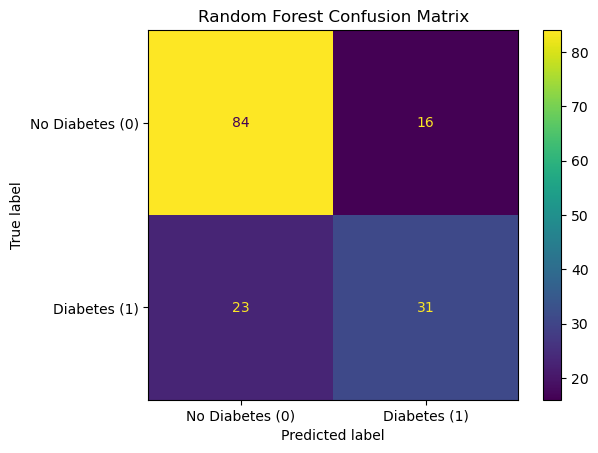

In [36]:
print("\\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_random_forest,
    target_names=["No Diabetes (0)", "Diabetes (1)"],
    zero_division=0
))

print("Confusion Matrix:")
cm_random_forest = confusion_matrix(y_test, y_pred_random_forest)
print(cm_random_forest)

ConfusionMatrixDisplay(
    confusion_matrix=cm_random_forest,
    display_labels=["No Diabetes (0)", "Diabetes (1)"]
).plot()
plt.title("Random Forest Confusion Matrix")
plt.show()


ROC-AUC  : 0.8194


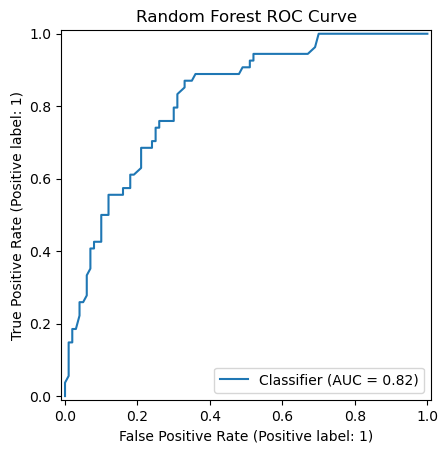

In [37]:
y_prob_random_forest = random_forest.predict_proba(X_test)[:, 1]
print(f"ROC-AUC  : {roc_auc_score(y_test, y_prob_random_forest):.4f}")

RocCurveDisplay.from_predictions(y_test, y_prob_random_forest)
plt.title("Random Forest ROC Curve")
plt.show()


## Gaussian Naive Bayes Model Training and Evaluation.

In [38]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, RocCurveDisplay
)
import matplotlib.pyplot as plt

naive_bayes = GaussianNB()
naive_bayes.fit(X_train, y_train)


,priors,None
,var_smoothing,1e-09


In [39]:
y_pred_naive_bayes = naive_bayes.predict(X_test)

accuracy_naive_bayes = accuracy_score(y_test, y_pred_naive_bayes)
precision_naive_bayes = precision_score(y_test, y_pred_naive_bayes, zero_division=0)
recall_naive_bayes = recall_score(y_test, y_pred_naive_bayes, zero_division=0)
f1_naive_bayes = f1_score(y_test, y_pred_naive_bayes, zero_division=0)

print("Gaussian Naive Bayes — Test Results")
print("-" * 45)
print(f"Accuracy : {accuracy_naive_bayes:.4f} ({accuracy_naive_bayes * 100:.2f}%)")
print(f"Precision: {precision_naive_bayes:.4f}")
print(f"Recall   : {recall_naive_bayes:.4f}")
print(f"F1-score : {f1_naive_bayes:.4f}")


Gaussian Naive Bayes — Test Results
---------------------------------------------
Accuracy : 0.6948 (69.48%)
Precision: 0.5574
Recall   : 0.6296
F1-score : 0.5913


\nClassification Report:
                 precision    recall  f1-score   support

No Diabetes (0)       0.78      0.73      0.76       100
   Diabetes (1)       0.56      0.63      0.59        54

       accuracy                           0.69       154
      macro avg       0.67      0.68      0.67       154
   weighted avg       0.71      0.69      0.70       154

Confusion Matrix:
[[73 27]
 [20 34]]


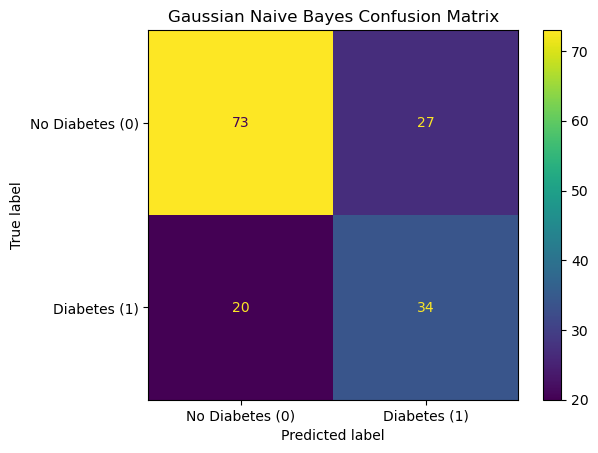

In [40]:
print("\\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_naive_bayes,
    target_names=["No Diabetes (0)", "Diabetes (1)"],
    zero_division=0
))

print("Confusion Matrix:")
cm_naive_bayes = confusion_matrix(y_test, y_pred_naive_bayes)
print(cm_naive_bayes)

ConfusionMatrixDisplay(
    confusion_matrix=cm_naive_bayes,
    display_labels=["No Diabetes (0)", "Diabetes (1)"]
).plot()
plt.title("Gaussian Naive Bayes Confusion Matrix")
plt.show()


ROC-AUC  : 0.7696


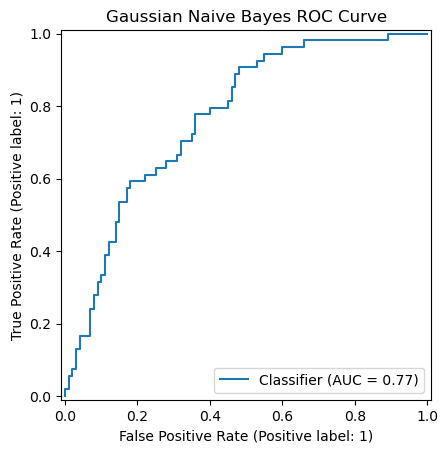

In [41]:
y_prob_naive_bayes = naive_bayes.predict_proba(X_test)[:, 1]
print(f"ROC-AUC  : {roc_auc_score(y_test, y_prob_naive_bayes):.4f}")

RocCurveDisplay.from_predictions(y_test, y_prob_naive_bayes)
plt.title("Gaussian Naive Bayes ROC Curve")
plt.show()


## Compare All Models

In [42]:
model_comparison = pd.DataFrame([
    {
        "Model": "KNN",
        "Accuracy": accuracy_score(y_test, knn.predict(X_test_scaled)),
        "Precision": precision_score(y_test, knn.predict(X_test_scaled), zero_division=0),
        "Recall": recall_score(y_test, knn.predict(X_test_scaled), zero_division=0),
        "F1-score": f1_score(y_test, knn.predict(X_test_scaled), zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, knn.predict_proba(X_test_scaled)[:, 1])
    },
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_logreg, "Precision": precision_logreg,
        "Recall": recall_logreg, "F1-score": f1_logreg,
        "ROC-AUC": roc_auc_score(y_test, logreg.predict_proba(X_test_scaled)[:, 1])
    },
    {
        "Model": "SVM",
        "Accuracy": accuracy_svm, "Precision": precision_svm,
        "Recall": recall_svm, "F1-score": f1_svm,
        "ROC-AUC": roc_auc_score(y_test, svm.predict_proba(X_test_scaled)[:, 1])
    },
    {
        "Model": "Decision Tree",
        "Accuracy": accuracy_decision_tree, "Precision": precision_decision_tree,
        "Recall": recall_decision_tree, "F1-score": f1_decision_tree,
        "ROC-AUC": roc_auc_score(y_test, decision_tree.predict_proba(X_test)[:, 1])
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_random_forest, "Precision": precision_random_forest,
        "Recall": recall_random_forest, "F1-score": f1_random_forest,
        "ROC-AUC": roc_auc_score(y_test, random_forest.predict_proba(X_test)[:, 1])
    },
    {
        "Model": "Gaussian Naive Bayes",
        "Accuracy": accuracy_naive_bayes, "Precision": precision_naive_bayes,
        "Recall": recall_naive_bayes, "F1-score": f1_naive_bayes,
        "ROC-AUC": roc_auc_score(y_test, naive_bayes.predict_proba(X_test)[:, 1])
    },
]).sort_values(by="ROC-AUC", ascending=False).reset_index(drop=True)

display(model_comparison)


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Random Forest,0.746753,0.659574,0.574074,0.613861,0.819352
1,Logistic Regression,0.694805,0.577778,0.481481,0.525253,0.811667
2,KNN,0.733766,0.618182,0.629630,0.623853,0.797500
3,SVM,0.733766,0.644444,0.537037,0.585859,0.791204
4,Gaussian Naive Bayes,0.694805,0.557377,0.629630,0.591304,0.769630
5,Decision Tree,0.668831,0.533333,0.444444,0.484848,0.617222


In [43]:
best_model = random_forest

In [44]:
%pip install joblib

Note: you may need to restart the kernel to use updated packages.


In [45]:
import joblib

joblib.dump(best_model, "diabetes_model.pkl")

print("Model exported successfully!")

Model exported successfully!
